In [20]:
# ============================================================
# CARDIOSAM-MEM — ECHONET-DYNAMIC TRAINING CONFIGURATION
# Same SAM2 + reliability-memory + topology + temporal novelties
# ============================================================
import os, random, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

ECHONET_ROOT = "/kaggle/input/datasets/mahnurrahman/echonet-dynamic/EchoNet-Dynamic"
ECHONET_VIDEO_DIR = os.path.join(ECHONET_ROOT, "Videos")
ECHONET_FILELIST = os.path.join(ECHONET_ROOT, "FileList.csv")
ECHONET_TRACINGS = os.path.join(ECHONET_ROOT, "VolumeTracings.csv")

IMAGE_SIZE = 256
SEQ_LEN = 8
BATCH_SIZE = 2
NUM_WORKERS = 2

# Runtime-conscious, EF-balanced subsets. Increase later only if desired.
N_TRAIN = 300
N_VAL = 50
N_TEST = 100

for p in [ECHONET_VIDEO_DIR, ECHONET_FILELIST, ECHONET_TRACINGS]:
    print(p, "->", os.path.exists(p))


/kaggle/input/datasets/mahnurrahman/echonet-dynamic/EchoNet-Dynamic/Videos -> True
/kaggle/input/datasets/mahnurrahman/echonet-dynamic/EchoNet-Dynamic/FileList.csv -> True
/kaggle/input/datasets/mahnurrahman/echonet-dynamic/EchoNet-Dynamic/VolumeTracings.csv -> True


In [21]:
# ============================================================
# LOAD + HARMONIZE ECHONET METADATA
# ============================================================
filelist_df = pd.read_csv(ECHONET_FILELIST)
tracing_df = pd.read_csv(ECHONET_TRACINGS)
filelist_df["FileKey"] = filelist_df["FileName"].astype(str).str.replace(".avi", "", regex=False)
tracing_df["FileKey"] = tracing_df["FileName"].astype(str).str.replace(".avi", "", regex=False)

traced_frames = tracing_df.groupby("FileKey")["Frame"].nunique()
eligible_keys = set(traced_frames[traced_frames >= 2].index)
meta = filelist_df[filelist_df["FileKey"].isin(eligible_keys)].copy().reset_index(drop=True)

print("FileList:", filelist_df.shape)
print("Tracings:", tracing_df.shape)
print("Eligible videos with >=2 annotated frames:", len(meta))
print(meta["Split"].str.upper().value_counts())
print("EF range:", float(meta.EF.min()), "to", float(meta.EF.max()))


FileList: (10030, 10)
Tracings: (425010, 7)
Eligible videos with >=2 annotated frames: 10024
Split
TRAIN    7460
VAL      1288
TEST     1276
Name: count, dtype: int64
EF range: 6.907258122 to 96.96723658


In [22]:
# ============================================================
# REPRODUCIBLE EF-BALANCED SUBSET SELECTION
# Preserves official TRAIN / VAL / TEST separation (no leakage).
# ============================================================
def balanced_ef_sample(df, n, seed=42, bins=5):
    df = df.copy().reset_index(drop=True)
    if len(df) <= n:
        return df
    # Rank first so qcut remains stable even with tied EF values.
    q = min(bins, max(2, df["EF"].nunique()))
    df["EF_bin"] = pd.qcut(df["EF"].rank(method="first"), q=q, labels=False)
    rng = np.random.default_rng(seed)
    chosen = []
    base = n // q
    remainder = n % q
    for b in range(q):
        idx = df.index[df["EF_bin"] == b].to_numpy()
        take = min(len(idx), base + (1 if b < remainder else 0))
        chosen.extend(rng.choice(idx, size=take, replace=False).tolist())
    if len(chosen) < n:
        remaining = np.setdiff1d(df.index.to_numpy(), np.asarray(chosen))
        extra = rng.choice(remaining, size=min(n-len(chosen), len(remaining)), replace=False)
        chosen.extend(extra.tolist())
    return df.loc[sorted(chosen[:n])].reset_index(drop=True)

def official_split(name):
    return meta[meta["Split"].astype(str).str.upper().eq(name)].copy().reset_index(drop=True)

train_meta = balanced_ef_sample(official_split("TRAIN"), N_TRAIN, SEED)
val_meta   = balanced_ef_sample(official_split("VAL"),   N_VAL,   SEED+1)
test_meta  = balanced_ef_sample(official_split("TEST"),  N_TEST,  SEED+2)

print("Selected TRAIN:", len(train_meta), "EF mean/std:", train_meta.EF.mean(), train_meta.EF.std())
print("Selected VAL  :", len(val_meta),   "EF mean/std:", val_meta.EF.mean(), val_meta.EF.std())
print("Selected TEST :", len(test_meta),  "EF mean/std:", test_meta.EF.mean(), test_meta.EF.std())
assert set(train_meta.FileKey).isdisjoint(set(val_meta.FileKey))
assert set(train_meta.FileKey).isdisjoint(set(test_meta.FileKey))
assert set(val_meta.FileKey).isdisjoint(set(test_meta.FileKey))
print("✓ No video leakage across splits")


Selected TRAIN: 300 EF mean/std: 55.65139008768667 12.490115366298213
Selected VAL  : 50 EF mean/std: 56.494858191599995 11.227579525725725
Selected TEST : 100 EF mean/std: 55.86703644919999 12.659144810992778
✓ No video leakage across splits


In [23]:
# ============================================================
# ECHONET TRACING -> LV CAVITY MASK
# ============================================================
def tracing_to_mask(rows, height, width):
    rows = rows.copy().sort_values("Y1")
    side1 = rows[["X1","Y1"]].to_numpy(np.float32)
    side2 = rows[["X2","Y2"]].to_numpy(np.float32)
    points = np.concatenate([side1, side2[::-1]], axis=0)
    points = points[np.isfinite(points).all(axis=1)]
    mask = np.zeros((height, width), dtype=np.uint8)
    if len(points) < 3:
        return mask
    points[:,0] = np.clip(points[:,0], 0, width-1)
    points[:,1] = np.clip(points[:,1], 0, height-1)
    cv2.fillPoly(mask, [np.round(points).astype(np.int32)], 1)
    return mask

def normalize_echo(img):
    img = img.astype(np.float32)
    nz = img[img > 0]
    if len(nz):
        lo, hi = np.percentile(nz, [1,99])
        img = np.clip(img, lo, hi)
        if hi > lo: img = (img-lo)/(hi-lo)
    return np.clip(img,0,1)


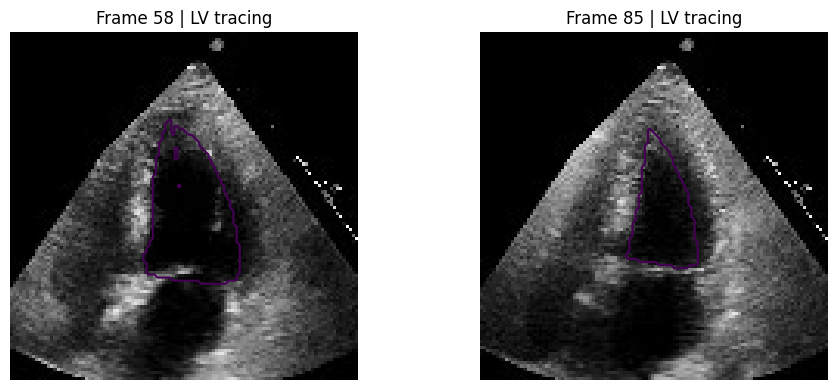

IMPORTANT: visually confirm both LV masks are correct before continuing.


In [24]:
# ============================================================
# VERIFY ONE ECHONET TRACING BEFORE TRAINING
# ============================================================
key = train_meta.iloc[0].FileKey
rows_all = tracing_df[tracing_df.FileKey.eq(key)]
ann = sorted(rows_all.Frame.unique().astype(int).tolist())
cap = cv2.VideoCapture(os.path.join(ECHONET_VIDEO_DIR, key + ".avi"))
fig, axes = plt.subplots(1, 2, figsize=(10,4))
for j, fi in enumerate([ann[0], ann[-1]]):
    cap.set(cv2.CAP_PROP_POS_FRAMES, fi); ok, frame = cap.read()
    assert ok, f"Could not read {key} frame {fi}"
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    m = tracing_to_mask(rows_all[rows_all.Frame.eq(fi)], *gray.shape)
    axes[j].imshow(gray, cmap="gray"); axes[j].contour(m, levels=[0.5], linewidths=1.5)
    axes[j].set_title(f"Frame {fi} | LV tracing"); axes[j].axis("off")
cap.release(); plt.tight_layout(); plt.show()
print("IMPORTANT: visually confirm both LV masks are correct before continuing.")


In [25]:
# ============================================================
# ECHONET VIDEO DATASET
# First traced frame = SAM2 conditioning mask.
# Last traced frame  = supervised segmentation target.
# Intermediate video frames are unlabeled and used for memory/temporal modeling.
# ============================================================
class EchoNetVideoDataset(Dataset):
    def __init__(self, metadata, tracing_df, video_dir, seq_len=8, image_size=256):
        self.meta = metadata.reset_index(drop=True)
        self.tracing = tracing_df
        self.video_dir = video_dir
        self.seq_len = seq_len
        self.image_size = image_size
    def __len__(self): return len(self.meta)
    def _read(self, cap, idx):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx)); ok, frame = cap.read()
        if not ok: raise RuntimeError(f"Failed to read frame {idx}")
        return cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    def __getitem__(self, index):
        row = self.meta.iloc[index]; key = row.FileKey
        tr = self.tracing[self.tracing.FileKey.eq(key)]
        annotated = sorted(tr.Frame.unique().astype(int).tolist())
        start, end = annotated[0], annotated[-1]
        frame_ids = np.round(np.linspace(start, end, self.seq_len)).astype(int)
        frame_ids[0], frame_ids[-1] = start, end
        cap = cv2.VideoCapture(os.path.join(self.video_dir, key + ".avi"))
        frames=[]; first_gray=None; last_gray=None
        for k, fi in enumerate(frame_ids):
            g=self._read(cap,fi)
            if k==0: first_gray=g.copy()
            if k==len(frame_ids)-1: last_gray=g.copy()
            g=cv2.resize(normalize_echo(g),(self.image_size,self.image_size),interpolation=cv2.INTER_LINEAR)
            frames.append(np.stack([g,g,g],axis=0).astype(np.float32))
        cap.release()
        start_mask=tracing_to_mask(tr[tr.Frame.eq(start)], *first_gray.shape)
        end_mask=tracing_to_mask(tr[tr.Frame.eq(end)], *last_gray.shape)
        start_mask=cv2.resize(start_mask,(self.image_size,self.image_size),interpolation=cv2.INTER_NEAREST)
        end_mask=cv2.resize(end_mask,(self.image_size,self.image_size),interpolation=cv2.INTER_NEAREST)
        masks=np.zeros((self.seq_len,1,self.image_size,self.image_size),dtype=np.float32)
        masks[0,0]=start_mask; masks[-1,0]=end_mask
        return {"images":torch.from_numpy(np.stack(frames)), "masks":torch.from_numpy(masks),
                "file_key":key, "ef":float(row.EF), "start_frame":start, "end_frame":end}


In [26]:
# ============================================================
# BUILD TRAIN / VAL / TEST LOADERS
# ============================================================
train_dataset=EchoNetVideoDataset(train_meta,tracing_df,ECHONET_VIDEO_DIR,SEQ_LEN,IMAGE_SIZE)
val_dataset=EchoNetVideoDataset(val_meta,tracing_df,ECHONET_VIDEO_DIR,SEQ_LEN,IMAGE_SIZE)
test_dataset=EchoNetVideoDataset(test_meta,tracing_df,ECHONET_VIDEO_DIR,SEQ_LEN,IMAGE_SIZE)

train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS,pin_memory=True,drop_last=True)
val_loader=DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=True)
test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=True)
print("Train/Val/Test:",len(train_dataset),len(val_dataset),len(test_dataset))
b=next(iter(train_loader)); print("Images:",b["images"].shape,"Masks:",b["masks"].shape)
print("Supervised frames per video: t=0 conditioning, t=7 target")


Train/Val/Test: 300 50 100
Images: torch.Size([2, 8, 3, 256, 256]) Masks: torch.Size([2, 8, 1, 256, 256])
Supervised frames per video: t=0 conditioning, t=7 target


In [27]:
# ============================================================
# ECHONET DATA SANITY CHECK
# ============================================================
batch=next(iter(train_loader))
print("images",batch["images"].shape,batch["images"].min().item(),batch["images"].max().item())
print("masks ",batch["masks"].shape,torch.unique(batch["masks"]))
assert batch["images"].shape[1:] == (SEQ_LEN,3,IMAGE_SIZE,IMAGE_SIZE)
assert batch["masks"].shape[1:] == (SEQ_LEN,1,IMAGE_SIZE,IMAGE_SIZE)
assert batch["masks"][:,0].sum() > 0 and batch["masks"][:,-1].sum() > 0
print("✓ EchoNet video pipeline ready")


images torch.Size([2, 8, 3, 256, 256]) 0.0 1.0
masks  torch.Size([2, 8, 1, 256, 256]) tensor([0., 1.])
✓ EchoNet video pipeline ready


In [28]:
!pip install -q git+https://github.com/facebookresearch/sam2.git


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 708.2 kB/s eta 0:00:00 0:00:01
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 7.5 MB/s eta 0:00:00


In [29]:
!wget -q \
https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_tiny.pt \
-O /kaggle/working/sam2.1_hiera_tiny.pt

print("Checkpoint downloaded.")


Checkpoint downloaded.


In [30]:
import torch.nn as nn
import torch.nn.functional as F

EPS = 1e-6

def prediction_uncertainty(logits):

    p = torch.sigmoid(logits)

    entropy = -(
        p * torch.log(p + EPS)
        +
        (1-p) * torch.log(1-p + EPS)
    )

    # normalize binary entropy
    entropy = entropy / np.log(2)

    return entropy


In [31]:
# ============================================================
# DEVICE SETUP
# ============================================================

import torch

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


Device: cuda
GPU: Tesla T4


In [32]:
# ============================================================
# SOFT CENTROID + AREA — FIXED
# ============================================================

def soft_centroid(prob):

    B, C, H, W = prob.shape

    yy, xx = torch.meshgrid(
        torch.linspace(
            0, 1, H,
            device=prob.device,
            dtype=prob.dtype
        ),
        torch.linspace(
            0, 1, W,
            device=prob.device,
            dtype=prob.dtype
        ),
        indexing="ij"
    )

    # Remove channel dimension
    # [B,1,H,W] -> [B,H,W]
    p = prob[:, 0]

    mass = (
        p.sum(dim=(1, 2))
        + EPS
    )

    cx = (
        (p * xx).sum(dim=(1, 2))
        / mass
    )

    cy = (
        (p * yy).sum(dim=(1, 2))
        / mass
    )

    # Output: [B,2]
    return torch.stack(
        [cx, cy],
        dim=-1
    )


def soft_area(prob):

    return prob.mean(
        dim=(1, 2, 3)
    )


In [33]:
dummy = torch.rand(
    2, 1, 256, 256,
    device=DEVICE
)

print(
    "Centroid shape:",
    soft_centroid(dummy).shape
)

print(
    "Area shape:",
    soft_area(dummy).shape
)


Centroid shape: torch.Size([2, 2])
Area shape: torch.Size([2])


In [34]:
# ============================================================
# TEMPORAL ANATOMY LOSS — SECOND-ORDER JITTER CONTROL
# Preserves normal cardiac contraction/expansion while penalizing
# abrupt acceleration (temporal jitter) in area and centroid.
# ============================================================

def temporal_anatomy_loss(current_prob, previous_prob, previous2_prob=None):
    if previous_prob is None:
        return torch.tensor(0.0, device=current_prob.device, dtype=current_prob.dtype)

    area_now = soft_area(current_prob)
    area_prev = soft_area(previous_prob)
    center_now = soft_centroid(current_prob)
    center_prev = soft_centroid(previous_prob)

    # For the first propagated pair there is no acceleration estimate yet.
    if previous2_prob is None:
        # Small motion regularizer only; normal contraction is not forced to zero.
        center_step = torch.norm(center_now - center_prev, dim=-1).mean()
        return 0.25 * center_step

    area_prev2 = soft_area(previous2_prob)
    center_prev2 = soft_centroid(previous2_prob)

    # Second-order finite differences = jitter/acceleration, not motion itself.
    area_acc = torch.abs(
        area_now - 2.0 * area_prev + area_prev2
    ) / (area_prev.detach() + EPS)

    center_acc = torch.norm(
        center_now - 2.0 * center_prev + center_prev2,
        dim=-1
    )

    return area_acc.mean() + center_acc.mean()


In [35]:
# ============================================================
# BOUNDARY + DIFFERENTIABLE TOPOLOGY CONSTRAINT
# LV cavity should form one simply connected region (Euler ~= 1).
# ============================================================

def soft_erode(x):
    return -F.max_pool2d(-x, kernel_size=3, stride=1, padding=1)


def soft_boundary(x):
    eroded = soft_erode(x)
    return torch.clamp(x - eroded, min=0)


def boundary_loss(pred_prob, target):
    pred_edge = soft_boundary(pred_prob)
    gt_edge = soft_boundary(target)
    intersection = (pred_edge * gt_edge).sum(dim=(1, 2, 3))
    denominator = pred_edge.sum(dim=(1, 2, 3)) + gt_edge.sum(dim=(1, 2, 3))
    score = (2 * intersection + EPS) / (denominator + EPS)
    return 1 - score.mean()


def _soft_or(values, dim=0):
    """Differentiable OR for probabilities in [0,1]."""
    return 1.0 - torch.prod(1.0 - values.clamp(0, 1), dim=dim)


def soft_euler_characteristic(prob):
    """
    Differentiable cubical-complex Euler characteristic of a soft foreground.
    For a binary simply connected LV cavity, chi = components - holes = 1.
    Returns one value per sample.
    """
    p = prob[:, 0].clamp(0, 1)  # [B,H,W]
    B, H, W = p.shape

    # Faces: foreground pixels.
    F_faces = p.sum(dim=(1, 2))

    # Horizontal grid edges: occupied if either pixel touching the edge is FG.
    # Boundary edges have one adjacent pixel.
    top = p[:, 0, :].sum(dim=1)
    bottom = p[:, -1, :].sum(dim=1)
    if H > 1:
        h_internal = (1.0 - (1.0 - p[:, :-1, :]) * (1.0 - p[:, 1:, :])).sum(dim=(1, 2))
    else:
        h_internal = torch.zeros(B, device=p.device, dtype=p.dtype)

    # Vertical grid edges.
    left = p[:, :, 0].sum(dim=1)
    right = p[:, :, -1].sum(dim=1)
    if W > 1:
        v_internal = (1.0 - (1.0 - p[:, :, :-1]) * (1.0 - p[:, :, 1:])).sum(dim=(1, 2))
    else:
        v_internal = torch.zeros(B, device=p.device, dtype=p.dtype)

    E_edges = top + bottom + left + right + h_internal + v_internal

    # Grid vertices: OR of up to four incident pixels. Padding with zero FG
    # lets one expression handle interior and boundary vertices.
    q = F.pad(p, (1, 1, 1, 1), value=0.0)
    a = q[:, :-1, :-1]
    b = q[:, :-1, 1:]
    c = q[:, 1:, :-1]
    d = q[:, 1:, 1:]
    V_vertices = (1.0 - (1-a)*(1-b)*(1-c)*(1-d)).sum(dim=(1, 2))

    return V_vertices - E_edges + F_faces


def topology_loss(pred_prob, target):
    """Match predicted Euler topology to GT and LV prior chi=1."""
    chi_pred = soft_euler_characteristic(pred_prob)
    with torch.no_grad():
        chi_gt = soft_euler_characteristic(target.float())

    match_gt = torch.abs(chi_pred - chi_gt)
    lv_prior = torch.abs(chi_pred - 1.0)
    # Smooth bounded penalty so scale stays compatible with existing weights.
    return (torch.tanh(match_gt) + 0.5 * torch.tanh(lv_prior)).mean()


def anatomical_topology_loss(pred_prob, target):
    # Keep the SAME overall 0.15 loss weight later; split internally.
    return 0.5 * boundary_loss(pred_prob, target) + 0.5 * topology_loss(pred_prob, target)


In [36]:
def dice_loss(
    logits,
    target
):

    probability = torch.sigmoid(
        logits
    )

    intersection = (
        probability*target
    ).sum(dim=(1,2,3))

    denominator = (
        probability.sum(dim=(1,2,3))
        +
        target.sum(dim=(1,2,3))
    )

    dice = (
        2*intersection + EPS
    ) / (
        denominator + EPS
    )

    return 1-dice.mean()


def segmentation_loss(
    logits,
    target
):

    dice = dice_loss(
        logits,
        target
    )

    bce = F.binary_cross_entropy_with_logits(
        logits,
        target
    )

    return 0.7*dice + 0.3*bce


In [37]:
def cardio_reliability(
    current_logits,
    previous_prob=None
):

    prob = torch.sigmoid(
        current_logits
    )

    # -----------------------------------------
    # Confidence reliability
    # -----------------------------------------
    uncertainty = prediction_uncertainty(
        current_logits
    )

    confidence = (
        1-uncertainty
    ).mean(dim=(1,2,3))

    if previous_prob is None:

        temporal = torch.ones_like(
            confidence
        )

        anatomy = torch.ones_like(
            confidence
        )

    else:

        # -----------------------------------------
        # Anatomical area plausibility
        # -----------------------------------------

        area_now = soft_area(prob)
        area_prev = soft_area(
            previous_prob
        )

        relative_area_change = (
            torch.abs(
                area_now-area_prev
            )
            /
            (area_prev+EPS)
        )

        anatomy = torch.exp(
            -2.0*relative_area_change
        )

        # -----------------------------------------
        # Temporal centroid consistency
        # -----------------------------------------

        center_now = soft_centroid(
            prob
        )

        center_prev = soft_centroid(
            previous_prob
        )

        displacement = torch.norm(
            center_now-center_prev,
            dim=-1
        )

        temporal = torch.exp(
            -5.0*displacement
        )

    reliability = (
        confidence *
        anatomy *
        temporal
    )

    return torch.clamp(
        reliability,
        0,
        1
    )


In [38]:
# ============================================================
# LOAD SAM2.1 HIERA-TINY
# ============================================================

import os
import torch

from sam2.build_sam import build_sam2

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------

SAM2_CHECKPOINT = "/kaggle/working/sam2.1_hiera_tiny.pt"

# IMPORTANT:
# build_sam2 expects Hydra config name, not a local absolute path
SAM2_CONFIG = "configs/sam2.1/sam2.1_hiera_t.yaml"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Checkpoint exists:", os.path.exists(SAM2_CHECKPOINT))
print("Config:", SAM2_CONFIG)

assert os.path.exists(SAM2_CHECKPOINT), (
    f"Checkpoint not found: {SAM2_CHECKPOINT}"
)

# ------------------------------------------------------------
# BUILD MODEL
# ------------------------------------------------------------

sam2 = build_sam2(
    SAM2_CONFIG,
    SAM2_CHECKPOINT,
    device=DEVICE
)

print("\nSAM2 successfully loaded!")
print("Model type:", type(sam2))

# ------------------------------------------------------------
# MEMORY ENCODER
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MEMORY ENCODER")
print("=" * 70)

print(sam2.memory_encoder)

# ------------------------------------------------------------
# MEMORY ATTENTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MEMORY ATTENTION")
print("=" * 70)

print(sam2.memory_attention)

# ------------------------------------------------------------
# IMAGE ENCODER
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("IMAGE ENCODER")
print("=" * 70)

print(type(sam2.image_encoder))

# ------------------------------------------------------------
# MASK DECODER
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MASK DECODER")
print("=" * 70)

if hasattr(sam2, "sam_mask_decoder"):
    print(sam2.sam_mask_decoder)
else:
    print("sam_mask_decoder attribute not found")

# ------------------------------------------------------------
# PARAMETER COUNT
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in sam2.parameters()
)

trainable_params = sum(
    p.numel()
    for p in sam2.parameters()
    if p.requires_grad
)

print("\n" + "=" * 70)
print("PARAMETERS")
print("=" * 70)

print(
    f"Total parameters: "
    f"{total_params / 1e6:.2f} M"
)

print(
    f"Currently trainable: "
    f"{trainable_params / 1e6:.2f} M"
)

# ------------------------------------------------------------
# FIND MEMORY-RELATED MODULES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MEMORY / DECODER MODULE NAMES")
print("=" * 70)

for name, module in sam2.named_modules():

    if (
        "memory" in name.lower()
        or "mask_decoder" in name.lower()
    ):

        print(
            f"{name:60s} -> "
            f"{module.__class__.__name__}"
        )


Device: cuda
Checkpoint exists: True
Config: configs/sam2.1/sam2.1_hiera_t.yaml

SAM2 successfully loaded!
Model type: <class 'sam2.modeling.sam2_base.SAM2Base'>

MEMORY ENCODER
MemoryEncoder(
  (mask_downsampler): MaskDownSampler(
    (encoder): Sequential(
      (0): Conv2d(1, 4, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): LayerNorm2d()
      (2): GELU(approximate='none')
      (3): Conv2d(4, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (4): LayerNorm2d()
      (5): GELU(approximate='none')
      (6): Conv2d(16, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (7): LayerNorm2d()
      (8): GELU(approximate='none')
      (9): Conv2d(64, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (10): LayerNorm2d()
      (11): GELU(approximate='none')
      (12): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    )
  )
  (pix_feat_proj): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
  (fuser): Fuser(
    (proj): Identity()
   

In [39]:
# ============================================================
# PHASE 9 — FREEZE / UNFREEZE CARDIOSAM-MEM
# ============================================================

# Freeze everything
for p in sam2.parameters():
    p.requires_grad = False

# Train SAM2 memory encoder
for p in sam2.memory_encoder.parameters():
    p.requires_grad = True

# Train SAM2 memory attention
for p in sam2.memory_attention.parameters():
    p.requires_grad = True

# Train mask decoder
for p in sam2.sam_mask_decoder.parameters():
    p.requires_grad = True


total = sum(p.numel() for p in sam2.parameters())
trainable = sum(
    p.numel()
    for p in sam2.parameters()
    if p.requires_grad
)

print(f"Total:     {total/1e6:.2f} M")
print(f"Trainable: {trainable/1e6:.2f} M")
print(
    f"Trainable percentage: "
    f"{100*trainable/total:.2f}%"
)

sam2.train()


Total:     38.96 M
Trainable: 11.52 M
Trainable percentage: 29.57%


SAM2Base(
  (image_encoder): ImageEncoder(
    (trunk): Hiera(
      (patch_embed): PatchEmbed(
        (proj): Conv2d(3, 96, kernel_size=(7, 7), stride=(4, 4), padding=(3, 3))
      )
      (blocks): ModuleList(
        (0): MultiScaleBlock(
          (norm1): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (attn): MultiScaleAttention(
            (qkv): Linear(in_features=96, out_features=288, bias=True)
            (proj): Linear(in_features=96, out_features=96, bias=True)
          )
          (drop_path): Identity()
          (norm2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (mlp): MLP(
            (layers): ModuleList(
              (0): Linear(in_features=96, out_features=384, bias=True)
              (1): Linear(in_features=384, out_features=96, bias=True)
            )
            (act): GELU(approximate='none')
          )
        )
        (1): MultiScaleBlock(
          (norm1): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
      

In [40]:
# ============================================================
# LEARNABLE CARDIAC RELIABILITY GATE
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

class CardiacReliabilityGate(nn.Module):
    """
    Learns memory reliability from:
       1. prediction confidence
       2. anatomical plausibility
       3. temporal consistency
    """

    def __init__(self):
        super().__init__()

        self.gate = nn.Sequential(
            nn.Linear(3, 16),
            nn.GELU(),
            nn.Linear(16, 1),
            nn.Sigmoid()
        )

    def forward(
        self,
        confidence,
        anatomy,
        temporal
    ):

        x = torch.stack(
            [confidence, anatomy, temporal],
            dim=-1
        )

        return self.gate(x).squeeze(-1)


reliability_gate = CardiacReliabilityGate().to(DEVICE)

print(reliability_gate)

print(
    "Gate parameters:",
    sum(
        p.numel()
        for p in reliability_gate.parameters()
    )
)


CardiacReliabilityGate(
  (gate): Sequential(
    (0): Linear(in_features=3, out_features=16, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=16, out_features=1, bias=True)
    (3): Sigmoid()
  )
)
Gate parameters: 81


In [41]:
# ============================================================
# RELIABILITY COMPONENTS — CONFIDENCE + ANATOMY + TEMPORAL
# ============================================================

EPS = 1e-6


def reliability_components(logits, previous_prob=None):
    prob = torch.sigmoid(logits)

    # 1) Prediction confidence from normalized binary entropy.
    entropy = -(prob * torch.log(prob + EPS) + (1-prob) * torch.log(1-prob + EPS))
    entropy = entropy / np.log(2)
    confidence = (1 - entropy).mean(dim=(1, 2, 3))

    if previous_prob is None:
        anatomy = torch.ones_like(confidence)
        temporal = torch.ones_like(confidence)
        return confidence, anatomy, temporal

    # 2) Anatomical plausibility.
    # Allow physiologic frame-to-frame area change up to 15% without penalty.
    area_now = soft_area(prob)
    area_previous = soft_area(previous_prob)
    relative_change = torch.abs(area_now - area_previous) / (area_previous + EPS)
    excess_change = torch.relu(relative_change - 0.15)
    anatomy = torch.exp(-2.0 * excess_change)

    # 3) Temporal consistency from normalized centroid displacement.
    centroid_now = soft_centroid(prob)
    centroid_previous = soft_centroid(previous_prob)
    displacement = torch.norm(centroid_now - centroid_previous, dim=-1)
    temporal = torch.exp(-5.0 * displacement)

    return confidence, anatomy, temporal


In [42]:
def compute_reliability(
    logits,
    previous_prob=None
):

    confidence, anatomy, temporal = (
        reliability_components(
            logits,
            previous_prob
        )
    )

    reliability = reliability_gate(
        confidence,
        anatomy,
        temporal
    )

    return (
        reliability,
        confidence,
        anatomy,
        temporal
    )


In [43]:
# ============================================================
# CARDIOSAM-MEM LOSS — FULL NOVELTY OBJECTIVE
# Existing global weights are preserved: 0.15 anatomy/topology + 0.10 temporal.
# ============================================================

def cardio_loss(logits, target, previous_prob=None, previous2_prob=None):
    prob = torch.sigmoid(logits)

    # Standard segmentation.
    seg = segmentation_loss(logits, target)

    # Boundary + genuine differentiable topology constraint.
    topo = anatomical_topology_loss(prob, target)

    # Second-order temporal anatomy consistency.
    temporal = temporal_anatomy_loss(
        prob,
        previous_prob,
        previous2_prob
    )

    total = seg + 0.15 * topo + 0.10 * temporal

    return {
        "total": total,
        "seg": seg,
        "topology": topo,
        "temporal": temporal
    }


In [44]:
# ============================================================
# SAM2 IMAGE ENCODER SANITY TEST
# ============================================================

sam2.eval()

batch = next(iter(train_loader))

images = batch["images"].to(
    DEVICE,
    non_blocking=True
)

masks = batch["masks"].to(
    DEVICE,
    non_blocking=True
)

print("Input video:", images.shape)
print("GT video:", masks.shape)

# First frame
frame = images[:, 0]

print("Frame:", frame.shape)

with torch.no_grad():

    backbone_out = sam2.forward_image(
        frame
    )

print("\nBackbone output keys:")

if isinstance(backbone_out, dict):

    for key, value in backbone_out.items():

        if torch.is_tensor(value):

            print(
                key,
                tuple(value.shape)
            )

        elif isinstance(value, list):

            print(
                key,
                [
                    tuple(x.shape)
                    if torch.is_tensor(x)
                    else type(x)
                    for x in value
                ]
            )

        else:

            print(
                key,
                type(value)
            )


Input video: torch.Size([2, 8, 3, 256, 256])
GT video: torch.Size([2, 8, 1, 256, 256])
Frame: torch.Size([2, 3, 256, 256])

Backbone output keys:
vision_features (2, 256, 16, 16)
vision_pos_enc [(2, 256, 64, 64), (2, 256, 32, 32), (2, 256, 16, 16)]
backbone_fpn [(2, 32, 64, 64), (2, 64, 32, 32), (2, 256, 16, 16)]


In [45]:
import inspect

print(inspect.signature(sam2._track_step))


(frame_idx, is_init_cond_frame, current_vision_feats, current_vision_pos_embeds, feat_sizes, point_inputs, mask_inputs, output_dict, num_frames, track_in_reverse, prev_sam_mask_logits)


In [46]:
# ============================================================
# SAM2 FEATURE PREPARATION — FIXED FOR NATIVE SAM2 SIZE
# ============================================================

def prepare_sam2_features(model, frame):

    sam_size = model.image_size

    if isinstance(sam_size, (tuple, list)):
        target_size = tuple(sam_size)
    else:
        target_size = (sam_size, sam_size)

    # 256x256 dataset frame -> native SAM2 resolution
    if frame.shape[-2:] != target_size:

        frame = F.interpolate(
            frame,
            size=target_size,
            mode="bilinear",
            align_corners=False
        )

    backbone_out = model.forward_image(frame)

    _, vision_feats, vision_pos, feat_sizes = (
        model._prepare_backbone_features(
            backbone_out
        )
    )

    return (
        vision_feats,
        vision_pos,
        feat_sizes
    )


In [47]:
batch = next(iter(train_loader))

test_frame = batch["images"][:, 0].to(DEVICE)

with torch.no_grad():

    vf, vp, fs = prepare_sam2_features(
        sam2,
        test_frame
    )

print("SAM2 image size:", sam2.image_size)
print("Original frame:", test_frame.shape)
print("Feature sizes:", fs)
print("Final feature size:", fs[-1])
print(
    "Expected embedding size:",
    sam2.sam_image_embedding_size
)


SAM2 image size: 1024
Original frame: torch.Size([2, 3, 256, 256])
Feature sizes: [(256, 256), (128, 128), (64, 64)]
Final feature size: (64, 64)
Expected embedding size: 64


In [48]:
# ============================================================
# METRICS
# ============================================================

def batch_dice_from_logits(logits, target):

    if logits.shape[-2:] != target.shape[-2:]:
        logits = F.interpolate(
            logits,
            size=target.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

    pred = (
        torch.sigmoid(logits) > 0.5
    ).float()

    intersection = (
        pred * target
    ).sum(dim=(1,2,3))

    denominator = (
        pred.sum(dim=(1,2,3))
        +
        target.sum(dim=(1,2,3))
    )

    return (
        (2*intersection + 1e-6)
        /
        (denominator + 1e-6)
    ).mean()


def batch_iou_from_logits(logits, target):

    if logits.shape[-2:] != target.shape[-2:]:
        logits = F.interpolate(
            logits,
            size=target.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

    pred = (
        torch.sigmoid(logits) > 0.5
    ).float()

    intersection = (
        pred * target
    ).sum(dim=(1,2,3))

    union = (
        pred + target -
        pred*target
    ).sum(dim=(1,2,3))

    return (
        (intersection + 1e-6)
        /
        (union + 1e-6)
    ).mean()


In [49]:
# ============================================================
# CARDIOSAM-MEM VIDEO FORWARD — FULL RELIABILITY-GUIDED MEMORY
# Reliability now directly controls what enters SAM2 memory.
# ============================================================

def _gate_sam2_memory(current_out, reliability, previous_memory=None):
    """
    Soft memory admission/blending.
    High reliability -> write current memory strongly.
    Low reliability  -> retain more of previous reliable memory.
    This changes subsequent SAM2 predictions, so the reliability gate is
    trained end-to-end through future-frame segmentation loss.
    """
    if current_out.get("maskmem_features", None) is None:
        return current_out

    new_mem = current_out["maskmem_features"]
    r = reliability.view(-1, 1, 1, 1).to(dtype=new_mem.dtype)

    if previous_memory is not None and previous_memory.shape == new_mem.shape:
        # Detach previous state to avoid an unnecessarily long recurrent graph.
        gated_mem = r * new_mem + (1.0 - r) * previous_memory.detach()
    else:
        # Fallback soft admission when no compatible previous memory exists.
        gated_mem = r * new_mem

    # Do not mutate SAM2's returned dictionary in-place unexpectedly.
    out = dict(current_out)
    out["maskmem_features"] = gated_mem
    out["cardiac_reliability"] = reliability
    return out


def forward_video(model, images, masks, training=True):
    B, T, C, H, W = images.shape

    output_dict = {
        "cond_frame_outputs": {},
        "non_cond_frame_outputs": {}
    }

    frame_outputs = []
    reliability_values = []
    previous_prob = None
    previous_memory = None

    for t in range(T):
        frame = images[:, t]

        vision_feats, vision_pos, feat_sizes = prepare_sam2_features(model, frame)

        if t == 0:
            mask_inputs = F.interpolate(
                masks[:, t].float(),
                size=(model.image_size, model.image_size),
                mode="nearest"
            )
            is_init = True
        else:
            mask_inputs = None
            is_init = False

        current_out = model.track_step(
            frame_idx=t,
            is_init_cond_frame=is_init,
            current_vision_feats=vision_feats,
            current_vision_pos_embeds=vision_pos,
            feat_sizes=feat_sizes,
            point_inputs=None,
            mask_inputs=mask_inputs,
            output_dict=output_dict,
            num_frames=T,
            track_in_reverse=False,
            run_mem_encoder=True,
            prev_sam_mask_logits=None
        )

        logits = current_out["pred_masks"]
        logits_up = F.interpolate(
            logits,
            size=(H, W),
            mode="bilinear",
            align_corners=False
        )

        reliability, confidence, anatomy, temporal = compute_reliability(
            logits_up,
            previous_prob
        )
        reliability_values.append(reliability)

        # First GT-conditioned memory remains intact. Reliability gating begins
        # on propagated frames, where memory contamination can occur.
        if t == 0:
            gated_out = current_out
        else:
            gated_out = _gate_sam2_memory(
                current_out,
                reliability,
                previous_memory
            )

        if t == 0:
            output_dict["cond_frame_outputs"][t] = gated_out
        else:
            output_dict["non_cond_frame_outputs"][t] = gated_out

        if gated_out.get("maskmem_features", None) is not None:
            previous_memory = gated_out["maskmem_features"]

        frame_outputs.append(logits_up)
        previous_prob = torch.sigmoid(logits_up)

    predictions = torch.stack(frame_outputs, dim=1)
    reliability_values = torch.stack(reliability_values, dim=1)
    return predictions, reliability_values


In [50]:
# ============================================================
# ECHONET VIDEO LOSS — ENDPOINT SUPERVISION + FULL TEMPORAL NOVELTY
# EchoNet provides expert LV tracings at sparse annotated frames, not every video frame.
# t=0 is conditioning; t=-1 is the supervised target.
# Temporal second-order regularization uses predictions across the entire sequence.
# ============================================================
def compute_video_loss(predictions, targets):
    T=predictions.shape[1]
    final_logits=predictions[:,-1]; final_gt=targets[:,-1]
    seg=segmentation_loss(final_logits,final_gt)
    topo=anatomical_topology_loss(torch.sigmoid(final_logits),final_gt)
    temporal_terms=[]
    probs=torch.sigmoid(predictions)
    for t in range(2,T):
        temporal_terms.append(temporal_anatomy_loss(probs[:,t],probs[:,t-1],probs[:,t-2]))
    temporal=torch.stack(temporal_terms).mean() if temporal_terms else torch.zeros((),device=predictions.device)
    total=seg + 0.15*topo + 0.10*temporal
    return {"total":total,"seg":seg,"topology":topo,"temporal":temporal}


In [51]:
# ============================================================
# OPTIMIZER
# ============================================================

trainable_parameters = (
    [
        p for p in sam2.parameters()
        if p.requires_grad
    ]
    +
    list(reliability_gate.parameters())
)

optimizer = torch.optim.AdamW(
    trainable_parameters,
    lr=1e-5,
    weight_decay=1e-4
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print(
    "Optimized parameters:",
    sum(
        p.numel()
        for p in trainable_parameters
    ) / 1e6,
    "M"
)


Optimized parameters: 11.522102 M


In [52]:
# ============================================================
# ONE-BATCH FORWARD TEST
# ============================================================

sam2.train()
reliability_gate.train()

batch = next(iter(train_loader))

images = batch["images"].to(
    DEVICE,
    non_blocking=True
)

masks = batch["masks"].to(
    DEVICE,
    non_blocking=True
)

print("Images:", images.shape)
print("Masks :", masks.shape)

optimizer.zero_grad(
    set_to_none=True
)

with torch.amp.autocast(
    "cuda",
    enabled=torch.cuda.is_available()
):

    predictions, reliability = (
        forward_video(
            sam2,
            images,
            masks,
            training=True
        )
    )

    losses = compute_video_loss(
        predictions,
        masks
    )

print(
    "Predictions:",
    predictions.shape
)

print(
    "Reliability:",
    reliability.shape
)

print(
    "Reliability mean:",
    reliability.mean().item()
)

print(
    "Total loss:",
    losses["total"].item()
)

print(
    "Seg loss:",
    losses["seg"].item()
)

print(
    "Topology loss:",
    losses["topology"].item()
)

print(
    "Temporal loss:",
    losses["temporal"].item()
)

dice = batch_dice_from_logits(
    predictions[:, -1],
    masks[:, -1]
)

print(
    "Initial Dice:",
    dice.item()
)

# backward sanity test
scaler.scale(
    losses["total"]
).backward()

scaler.unscale_(
    optimizer
)

torch.nn.utils.clip_grad_norm_(
    trainable_parameters,
    1.0
)

scaler.step(
    optimizer
)

scaler.update()

print("\n✓ Forward/backward successful")


Images: torch.Size([2, 8, 3, 256, 256])
Masks : torch.Size([2, 8, 1, 256, 256])
Predictions: torch.Size([2, 8, 1, 256, 256])
Reliability: torch.Size([2, 8])
Reliability mean: 0.449951171875
Total loss: 0.32929861545562744
Seg loss: 0.14273518323898315
Topology loss: 1.199082612991333
Temporal loss: 0.06701042503118515
Initial Dice: 0.9025154113769531

✓ Forward/backward successful


In [53]:
# ============================================================
# TRAINING CONFIGURATION
# ============================================================

NUM_EPOCHS = 10

print("Training configuration")
print("Epochs       :", NUM_EPOCHS)
print("Device       :", DEVICE)
print("Trainable M  :", sum(
    p.numel() for p in trainable_parameters
) / 1e6)


Training configuration
Epochs       : 10
Device       : cuda
Trainable M  : 11.522102


In [54]:
# ============================================================
# SEGMENTATION METRICS
# ============================================================

@torch.no_grad()
def segmentation_metrics(
    logits,
    targets,
    threshold=0.5,
    eps=1e-7
):

    probs = torch.sigmoid(logits)

    preds = (
        probs > threshold
    ).float()

    targets = (
        targets > 0.5
    ).float()

    dims = (1, 2, 3)

    intersection = (
        preds * targets
    ).sum(dim=dims)

    pred_sum = preds.sum(dim=dims)
    target_sum = targets.sum(dim=dims)

    dice = (
        2.0 * intersection + eps
    ) / (
        pred_sum +
        target_sum +
        eps
    )

    union = (
        pred_sum +
        target_sum -
        intersection
    )

    iou = (
        intersection + eps
    ) / (
        union + eps
    )

    return (
        dice.mean().item(),
        iou.mean().item()
    )


In [55]:
# ============================================================
# TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(
    model,
    reliability_gate,
    loader,
    optimizer,
    scaler
):

    model.train()
    reliability_gate.train()

    running_total = 0.0
    running_seg = 0.0
    running_topology = 0.0
    running_temporal = 0.0

    running_dice = 0.0
    running_iou = 0.0
    running_reliability = 0.0

    num_batches = 0

    for batch_idx, batch in enumerate(loader):

        images = batch["images"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["masks"].to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):

            predictions, reliability = (
                forward_video(
                    model,
                    images,
                    masks,
                    training=True
                )
            )

            losses = compute_video_loss(
                predictions,
                masks
            )

        scaler.scale(
            losses["total"]
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            trainable_parameters,
            max_norm=1.0
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        # EchoNet: evaluate only the final expert-traced target frame
        metric_logits = predictions[:, -1]
        metric_masks = masks[:, -1]

        dice, iou = segmentation_metrics(
            metric_logits.detach(),
            metric_masks
        )

        running_total += (
            losses["total"].detach().item()
        )

        running_seg += (
            losses["seg"].detach().item()
        )

        running_topology += (
            losses["topology"].detach().item()
        )

        running_temporal += (
            losses["temporal"].detach().item()
        )

        running_dice += dice
        running_iou += iou

        running_reliability += (
            reliability.detach()
            .mean()
            .item()
        )

        num_batches += 1

        if (
            batch_idx == 0 or
            (batch_idx + 1) % 20 == 0
        ):

            print(
                f"  Batch "
                f"{batch_idx + 1:03d}/"
                f"{len(loader):03d} | "
                f"Loss {losses['total'].item():.4f} | "
                f"Dice {dice:.4f} | "
                f"IoU {iou:.4f}"
            )

    return {

        "loss":
            running_total / num_batches,

        "seg":
            running_seg / num_batches,

        "topology":
            running_topology / num_batches,

        "temporal":
            running_temporal / num_batches,

        "dice":
            running_dice / num_batches,

        "iou":
            running_iou / num_batches,

        "reliability":
            running_reliability / num_batches
    }


In [56]:
# ============================================================
# VALIDATION
# ============================================================

@torch.no_grad()
def validate_one_epoch(
    model,
    reliability_gate,
    loader
):

    model.eval()
    reliability_gate.eval()

    running_total = 0.0
    running_seg = 0.0
    running_topology = 0.0
    running_temporal = 0.0

    running_dice = 0.0
    running_iou = 0.0
    running_reliability = 0.0

    num_batches = 0

    for batch in loader:

        images = batch["images"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["masks"].to(
            DEVICE,
            non_blocking=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):

            predictions, reliability = (
                forward_video(
                    model,
                    images,
                    masks,
                    training=False
                )
            )

            losses = compute_video_loss(
                predictions,
                masks
            )

        # EchoNet: evaluate only the final expert-traced target frame
        metric_logits = predictions[:, -1]
        metric_masks = masks[:, -1]

        dice, iou = segmentation_metrics(
            metric_logits,
            metric_masks
        )

        running_total += (
            losses["total"].item()
        )

        running_seg += (
            losses["seg"].item()
        )

        running_topology += (
            losses["topology"].item()
        )

        running_temporal += (
            losses["temporal"].item()
        )

        running_dice += dice
        running_iou += iou

        running_reliability += (
            reliability.mean().item()
        )

        num_batches += 1

    return {

        "loss":
            running_total / num_batches,

        "seg":
            running_seg / num_batches,

        "topology":
            running_topology / num_batches,

        "temporal":
            running_temporal / num_batches,

        "dice":
            running_dice / num_batches,

        "iou":
            running_iou / num_batches,

        "reliability":
            running_reliability / num_batches
    }


In [57]:
# ============================================================
# LEARNING RATE SCHEDULER
# ============================================================

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=NUM_EPOCHS,
    eta_min=1e-7
)

print("Scheduler ready")


Scheduler ready


In [58]:
# ============================================================
# FULL TRAINING LOOP — NO EARLY STOPPING
# ============================================================

import os
import time

BEST_PATH = (
    "/kaggle/working/"
    "cardiosam_mem_echonet_best.pth"
)

FINAL_PATH = (
    "/kaggle/working/"
    "cardiosam_mem_echonet_final.pth"
)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_dice": [],
    "val_dice": [],
    "train_iou": [],
    "val_iou": [],
    "train_reliability": [],
    "val_reliability": [],
    "lr": []
}

best_val_dice = -1.0

for epoch in range(NUM_EPOCHS):

    start_time = time.time()

    print("\n" + "=" * 70)

    print(
        f"EPOCH "
        f"{epoch + 1:02d}/"
        f"{NUM_EPOCHS:02d}"
    )

    print("=" * 70)

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    train_stats = train_one_epoch(
        sam2,
        reliability_gate,
        train_loader,
        optimizer,
        scaler
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    val_stats = validate_one_epoch(
        sam2,
        reliability_gate,
        val_loader
    )

    current_lr = (
        optimizer.param_groups[0]["lr"]
    )

    # --------------------------------------------------------
    # HISTORY
    # --------------------------------------------------------

    history["train_loss"].append(
        train_stats["loss"]
    )

    history["val_loss"].append(
        val_stats["loss"]
    )

    history["train_dice"].append(
        train_stats["dice"]
    )

    history["val_dice"].append(
        val_stats["dice"]
    )

    history["train_iou"].append(
        train_stats["iou"]
    )

    history["val_iou"].append(
        val_stats["iou"]
    )

    history[
        "train_reliability"
    ].append(
        train_stats["reliability"]
    )

    history[
        "val_reliability"
    ].append(
        val_stats["reliability"]
    )

    history["lr"].append(
        current_lr
    )

    # --------------------------------------------------------
    # BEST CHECKPOINT
    # --------------------------------------------------------

    if val_stats["dice"] > best_val_dice:

        best_val_dice = (
            val_stats["dice"]
        )

        torch.save(
            {
                "epoch":
                    epoch + 1,

                "sam2_state_dict":
                    sam2.state_dict(),

                "reliability_gate_state_dict":
                    reliability_gate.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scheduler_state_dict":
                    scheduler.state_dict(),

                "scaler_state_dict":
                    scaler.state_dict(),

                "best_val_dice":
                    best_val_dice,

                "history":
                    history
            },
            BEST_PATH
        )

        best_message = "  <-- BEST SAVED"

    else:

        best_message = ""

    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler.step()

    epoch_time = (
        time.time() - start_time
    )

    # --------------------------------------------------------
    # DISPLAY
    # --------------------------------------------------------

    print("\nTRAIN")
    print(
        f"Loss        : "
        f"{train_stats['loss']:.4f}"
    )
    print(
        f"Dice        : "
        f"{train_stats['dice']:.4f}"
    )
    print(
        f"IoU         : "
        f"{train_stats['iou']:.4f}"
    )
    print(
        f"Reliability : "
        f"{train_stats['reliability']:.4f}"
    )

    print("\nVALIDATION")
    print(
        f"Loss        : "
        f"{val_stats['loss']:.4f}"
    )
    print(
        f"Dice        : "
        f"{val_stats['dice']:.4f}"
        f"{best_message}"
    )
    print(
        f"IoU         : "
        f"{val_stats['iou']:.4f}"
    )
    print(
        f"Reliability : "
        f"{val_stats['reliability']:.4f}"
    )

    print(
        f"\nLR          : "
        f"{current_lr:.2e}"
    )

    print(
        f"Epoch time  : "
        f"{epoch_time / 60:.2f} min"
    )

    print(
        f"Best Val Dice: "
        f"{best_val_dice:.4f}"
    )

# ============================================================
# SAVE FINAL EPOCH MODEL
# ============================================================

torch.save(
    {
        "epoch":
            NUM_EPOCHS,

        "sam2_state_dict":
            sam2.state_dict(),

        "reliability_gate_state_dict":
            reliability_gate.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "scheduler_state_dict":
            scheduler.state_dict(),

        "scaler_state_dict":
            scaler.state_dict(),

        "best_val_dice":
            best_val_dice,

        "history":
            history
    },
    FINAL_PATH
)

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print(
    "Best validation Dice:",
    round(best_val_dice, 4)
)

print(
    "Best checkpoint:",
    BEST_PATH
)

print(
    "Final checkpoint:",
    FINAL_PATH
)



EPOCH 01/10
  Batch 001/150 | Loss 0.3177 | Dice 0.8719 | IoU 0.7730
  Batch 020/150 | Loss 0.3402 | Dice 0.8313 | IoU 0.7236
  Batch 040/150 | Loss 0.2622 | Dice 0.9150 | IoU 0.8452
  Batch 060/150 | Loss 0.2379 | Dice 0.9334 | IoU 0.8755
  Batch 080/150 | Loss 0.2883 | Dice 0.8723 | IoU 0.7781
  Batch 100/150 | Loss 0.2713 | Dice 0.9045 | IoU 0.8290
  Batch 120/150 | Loss 0.2950 | Dice 0.8867 | IoU 0.7967
  Batch 140/150 | Loss 0.2246 | Dice 0.9473 | IoU 0.8999

TRAIN
Loss        : 0.2875
Dice        : 0.8870
IoU         : 0.8007
Reliability : 0.4506

VALIDATION
Loss        : 0.2779
Dice        : 0.8925  <-- BEST SAVED
IoU         : 0.8090
Reliability : 0.4505

LR          : 1.00e-05
Epoch time  : 14.65 min
Best Val Dice: 0.8925

EPOCH 02/10
  Batch 001/150 | Loss 0.2641 | Dice 0.9093 | IoU 0.8337
  Batch 020/150 | Loss 0.2373 | Dice 0.9334 | IoU 0.8752
  Batch 040/150 | Loss 0.3080 | Dice 0.8528 | IoU 0.7444
  Batch 060/150 | Loss 0.2620 | Dice 0.9073 | IoU 0.8305
  Batch 080/150 |

In [82]:
# ============================================================
# EVALUATION CONFIGURATION
# ============================================================

import os
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import (
    binary_erosion,
    distance_transform_edt
)

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

EVAL_DIR = "/kaggle/working/CardioSAM_Mem_EchoNet_Evaluation"

os.makedirs(
    EVAL_DIR,
    exist_ok=True
)

BEST_PATH = (
    "/kaggle/working/"
    "cardiosam_mem_echonet_best.pth"
)

print("Evaluation directory:", EVAL_DIR)
print("Checkpoint:", BEST_PATH)


Evaluation directory: /kaggle/working/CardioSAM_Mem_EchoNet_Evaluation
Checkpoint: /kaggle/working/cardiosam_mem_echonet_best.pth


In [83]:
# ============================================================
# LOAD BEST CHECKPOINT
# ============================================================

checkpoint = torch.load(
    BEST_PATH,
    map_location=DEVICE,
    weights_only=False
)

sam2.load_state_dict(
    checkpoint["sam2_state_dict"]
)

reliability_gate.load_state_dict(
    checkpoint["reliability_gate_state_dict"]
)

sam2.eval()
reliability_gate.eval()

print(
    "Loaded epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation Dice:",
    checkpoint["best_val_dice"]
)


Loaded epoch: 10
Best validation Dice: 0.905103235244751


In [85]:
# ============================================================
# COMPLETE SEGMENTATION METRICS
# ============================================================

def calculate_binary_metrics(
    pred,
    gt,
    eps=1e-7
):

    pred = pred.astype(bool)
    gt = gt.astype(bool)

    tp = np.logical_and(
        pred,
        gt
    ).sum()

    tn = np.logical_and(
        ~pred,
        ~gt
    ).sum()

    fp = np.logical_and(
        pred,
        ~gt
    ).sum()

    fn = np.logical_and(
        ~pred,
        gt
    ).sum()

    dice = (
        2 * tp + eps
    ) / (
        2 * tp + fp + fn + eps
    )

    iou = (
        tp + eps
    ) / (
        tp + fp + fn + eps
    )

    precision = (
        tp + eps
    ) / (
        tp + fp + eps
    )

    recall = (
        tp + eps
    ) / (
        tp + fn + eps
    )

    specificity = (
        tn + eps
    ) / (
        tn + fp + eps
    )

    f1 = dice

    accuracy = (
        tp + tn + eps
    ) / (
        tp + tn + fp + fn + eps
    )

    return {
        "Dice": dice,
        "IoU": iou,
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1": f1,
        "Accuracy": accuracy
    }


In [88]:
# ============================================================
# SURFACE DISTANCE METRICS
# ============================================================

def get_surface(mask):

    mask = mask.astype(bool)

    if mask.sum() == 0:
        return mask

    eroded = binary_erosion(mask)

    return np.logical_xor(
        mask,
        eroded
    )


def surface_distances(
    pred,
    gt
):

    pred = pred.astype(bool)
    gt = gt.astype(bool)

    if (
        pred.sum() == 0 or
        gt.sum() == 0
    ):
        return np.nan, np.nan

    pred_surface = get_surface(pred)
    gt_surface = get_surface(gt)

    gt_distance = distance_transform_edt(
        ~gt_surface
    )

    pred_distance = distance_transform_edt(
        ~pred_surface
    )

    d_pred_gt = gt_distance[
        pred_surface
    ]

    d_gt_pred = pred_distance[
        gt_surface
    ]

    all_distances = np.concatenate([
        d_pred_gt,
        d_gt_pred
    ])

    hd95 = np.percentile(
        all_distances,
        95
    )

    assd = (
        d_pred_gt.mean() +
        d_gt_pred.mean()
    ) / 2.0

    return hd95, assd


In [89]:
# ============================================================
# BOUNDARY F1
# ============================================================

def boundary_f1(
    pred,
    gt,
    tolerance=2,
    eps=1e-7
):

    pred_surface = get_surface(pred)
    gt_surface = get_surface(gt)

    if (
        pred_surface.sum() == 0 or
        gt_surface.sum() == 0
    ):
        return np.nan

    dist_gt = distance_transform_edt(
        ~gt_surface
    )

    dist_pred = distance_transform_edt(
        ~pred_surface
    )

    pred_match = (
        dist_gt[pred_surface]
        <= tolerance
    ).sum()

    gt_match = (
        dist_pred[gt_surface]
        <= tolerance
    ).sum()

    precision = (
        pred_match + eps
    ) / (
        pred_surface.sum() + eps
    )

    recall = (
        gt_match + eps
    ) / (
        gt_surface.sum() + eps
    )

    return (
        2 * precision * recall
    ) / (
        precision + recall + eps
    )


In [90]:
# ============================================================
# ECHONET HELD-OUT TEST EVALUATION — FINAL EXPERT-TRACED FRAME
# ============================================================
@torch.no_grad()
def evaluate_dataset(model,reliability_gate,loader,dataset_name="EchoNet-Dynamic"):
    model.eval(); reliability_gate.eval(); records=[]
    for batch_idx,batch in enumerate(loader):
        images=batch["images"].to(DEVICE,non_blocking=True); masks=batch["masks"].to(DEVICE,non_blocking=True)
        with torch.amp.autocast("cuda",enabled=torch.cuda.is_available()):
            predictions,reliability=forward_video(model,images,masks,training=False)
        preds=(torch.sigmoid(predictions[:,-1])>0.5).float()
        gt=masks[:,-1]
        for b in range(preds.shape[0]):
            p=preds[b,0].cpu().numpy().astype(np.uint8); g=gt[b,0].cpu().numpy().astype(np.uint8)
            metrics=calculate_binary_metrics(p,g); hd95,assd=surface_distances(p,g); bf1=boundary_f1(p,g)
            records.append({"Dataset":dataset_name,"FileName":batch["file_key"][b],"EF":float(batch["ef"][b]),
                            **metrics,"HD95":hd95,"ASSD":assd,"Boundary_F1":bf1,
                            "Reliability":float(reliability[b,-1].item())})
        if batch_idx==0 or (batch_idx+1)%10==0: print(f"{dataset_name}: {batch_idx+1}/{len(loader)} batches")
    return pd.DataFrame(records)


In [91]:
# ============================================================
# ECHONET HELD-OUT TEST LOADER CHECK
# ============================================================
print("EchoNet TEST videos:",len(test_dataset),"batches:",len(test_loader))
b=next(iter(test_loader)); print("Images:",b["images"].shape,"Masks:",b["masks"].shape)
print("✓ Held-out official TEST subset ready")


EchoNet TEST videos: 100 batches: 50
Images: torch.Size([2, 8, 3, 256, 256]) Masks: torch.Size([2, 8, 1, 256, 256])
✓ Held-out official TEST subset ready


In [92]:
# ============================================================
# RUN ECHONET INTERNAL HELD-OUT TEST
# ============================================================
echonet_results=evaluate_dataset(sam2,reliability_gate,test_loader,"EchoNet-Dynamic")
echonet_results.to_csv(os.path.join(EVAL_DIR,"EchoNet_frame_level_results.csv"),index=False)
display(echonet_results.head())


EchoNet-Dynamic: 1/50 batches
EchoNet-Dynamic: 10/50 batches
EchoNet-Dynamic: 20/50 batches
EchoNet-Dynamic: 30/50 batches
EchoNet-Dynamic: 40/50 batches
EchoNet-Dynamic: 50/50 batches


,Dataset,FileName,EF,Dice,IoU,Precision,Recall,Specificity,F1,Accuracy,HD95,ASSD,Boundary_F1,Reliability
0,EchoNet-Dynamic,0X13F7CAB4C719ACA3,44.967150,0.877671,0.782008,0.900051,0.856376,0.993652,0.877671,0.985062,15.811388,4.159783,0.344728,0.453125
1,EchoNet-Dynamic,0X15E22119724FDD7D,67.415904,0.954393,0.912764,0.927078,0.983366,0.995495,0.954393,0.994827,3.000000,1.184063,0.823231,0.453125
2,EchoNet-Dynamic,0X174090E59512E733,57.743051,0.907208,0.830175,0.880755,0.935300,0.986919,0.907208,0.982086,10.037407,3.299155,0.451234,0.453125
3,EchoNet-Dynamic,0X18916084CE523264,75.894294,0.794420,0.658952,0.718459,0.888342,0.990017,0.794420,0.987183,8.529114,3.860222,0.301274,0.453125
4,EchoNet-Dynamic,0X19BCCFDA31770A23,65.324292,0.934053,0.876266,0.932589,0.935522,0.994309,0.934053,0.989746,15.421972,2.907460,0.659124,0.452393


In [93]:
# ============================================================
# ECHONET SUMMARY
# ============================================================
METRIC_COLUMNS=["Dice","IoU","Precision","Recall","Specificity","F1","Accuracy","HD95","ASSD","Boundary_F1","Reliability"]
rows=[]
for m in METRIC_COLUMNS:
    v=echonet_results[m].dropna(); rows.append({"Metric":m,"Mean":v.mean(),"SD":v.std(),"Median":v.median(),"Min":v.min(),"Max":v.max()})
echonet_summary=pd.DataFrame(rows)
echonet_summary.to_csv(os.path.join(EVAL_DIR,"EchoNet_summary_metrics.csv"),index=False)
display(echonet_summary.round(4))


,Metric,Mean,SD,Median,Min,Max
0,Dice,0.8990,0.0550,0.9140,0.6444,0.9663
1,IoU,0.8206,0.0834,0.8416,0.4753,0.9348
2,Precision,0.8896,0.0938,0.9161,0.5615,0.9991
3,Recall,0.9181,0.0614,0.9352,0.7266,0.9986
4,Specificity,0.9918,0.0072,0.9934,0.9637,0.9999
5,F1,0.8990,0.0550,0.9140,0.6444,0.9663
6,Accuracy,0.9863,0.0078,0.9885,0.9565,0.9960
7,HD95,9.6135,5.9486,7.8922,2.0000,27.6852
8,ASSD,2.9545,1.3562,2.5418,0.9618,7.6441
9,Boundary_F1,0.5629,0.1733,0.5745,0.1563,0.9551


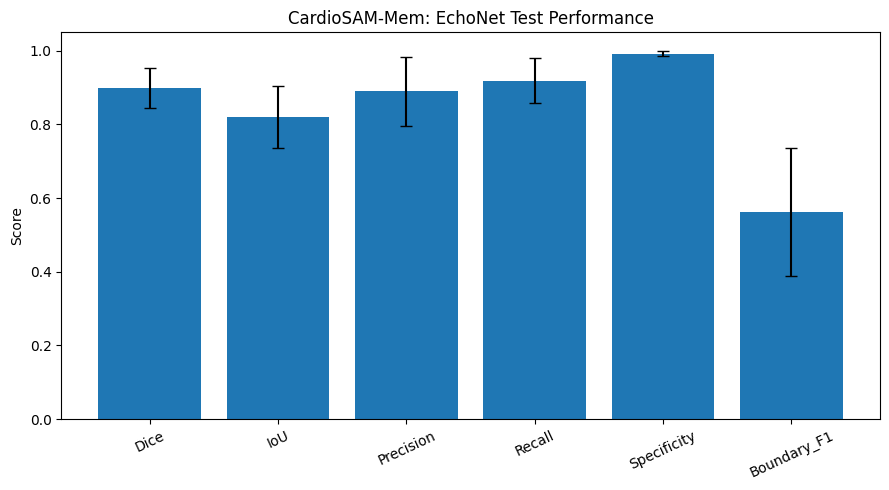

In [94]:
# ============================================================
# MAIN PERFORMANCE FIGURE
# ============================================================

main_metrics = [
    "Dice",
    "IoU",
    "Precision",
    "Recall",
    "Specificity",
    "Boundary_F1"
]

means = [
    echonet_results[m].mean()
    for m in main_metrics
]

stds = [
    echonet_results[m].std()
    for m in main_metrics
]

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    main_metrics,
    means,
    yerr=stds,
    capsize=4
)

plt.ylim(0, 1.05)

plt.ylabel("Score")

plt.title(
    "CardioSAM-Mem: EchoNet Test Performance"
)

plt.xticks(
    rotation=25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "EchoNet_Performance_Metrics.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()


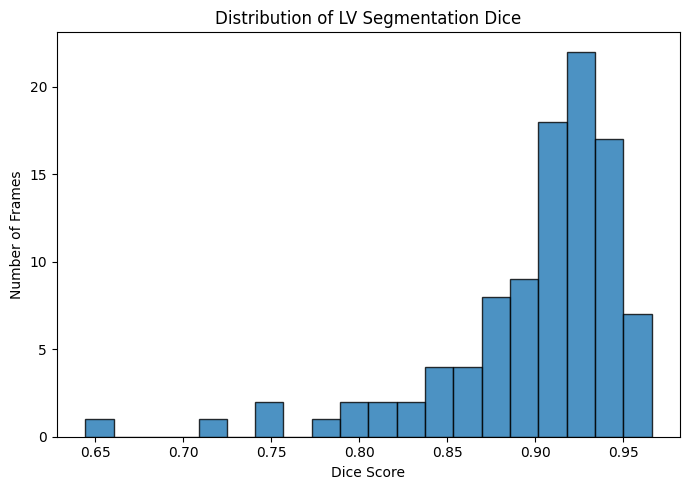

In [95]:
# ============================================================
# DICE DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(7, 5)
)

plt.hist(
    echonet_results["Dice"],
    bins=20,
    edgecolor="black",
    alpha=0.8
)

plt.xlabel("Dice Score")
plt.ylabel("Number of Frames")

plt.title(
    "Distribution of LV Segmentation Dice"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "EchoNet_Dice_Distribution.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()


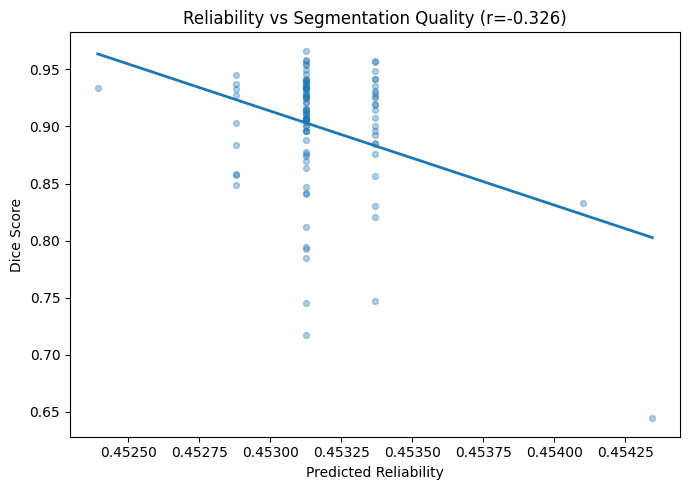

Reliability-Dice correlation: -0.3257608229796795


In [96]:
# ============================================================
# NOVELTY 1:
# RELIABILITY vs SEGMENTATION QUALITY
# ============================================================

x = echonet_results[
    "Reliability"
].values

y = echonet_results[
    "Dice"
].values

valid = (
    np.isfinite(x) &
    np.isfinite(y)
)

correlation = np.corrcoef(
    x[valid],
    y[valid]
)[0, 1]

plt.figure(
    figsize=(7, 5)
)

plt.scatter(
    x[valid],
    y[valid],
    alpha=0.35,
    s=18
)

if valid.sum() > 1:

    coef = np.polyfit(
        x[valid],
        y[valid],
        1
    )

    line_x = np.linspace(
        x[valid].min(),
        x[valid].max(),
        100
    )

    line_y = (
        coef[0] * line_x +
        coef[1]
    )

    plt.plot(
        line_x,
        line_y,
        linewidth=2
    )

plt.xlabel(
    "Predicted Reliability"
)

plt.ylabel(
    "Dice Score"
)

plt.title(
    f"Reliability vs Segmentation Quality "
    f"(r={correlation:.3f})"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "Novelty1_Reliability_vs_Dice.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()

print(
    "Reliability-Dice correlation:",
    correlation
)


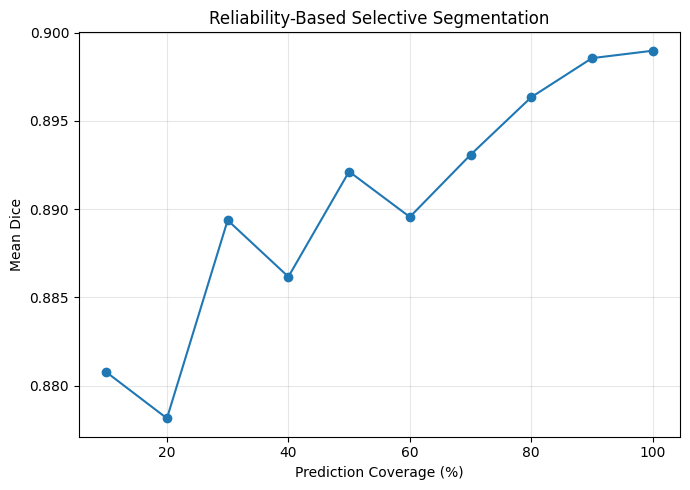

In [97]:
# ============================================================
# RELIABILITY SELECTIVE PERFORMANCE
# ============================================================

sorted_df = echonet_results.sort_values(
    "Reliability",
    ascending=False
).reset_index(drop=True)

coverage_levels = np.arange(
    0.1,
    1.01,
    0.1
)

coverage_dice = []

for coverage in coverage_levels:

    n = max(
        1,
        int(
            len(sorted_df)
            * coverage
        )
    )

    score = (
        sorted_df
        .iloc[:n]["Dice"]
        .mean()
    )

    coverage_dice.append(
        score
    )

plt.figure(
    figsize=(7, 5)
)

plt.plot(
    coverage_levels * 100,
    coverage_dice,
    marker="o"
)

plt.xlabel(
    "Prediction Coverage (%)"
)

plt.ylabel(
    "Mean Dice"
)

plt.title(
    "Reliability-Based Selective Segmentation"
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "Novelty1_Reliability_Selective_Performance.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()


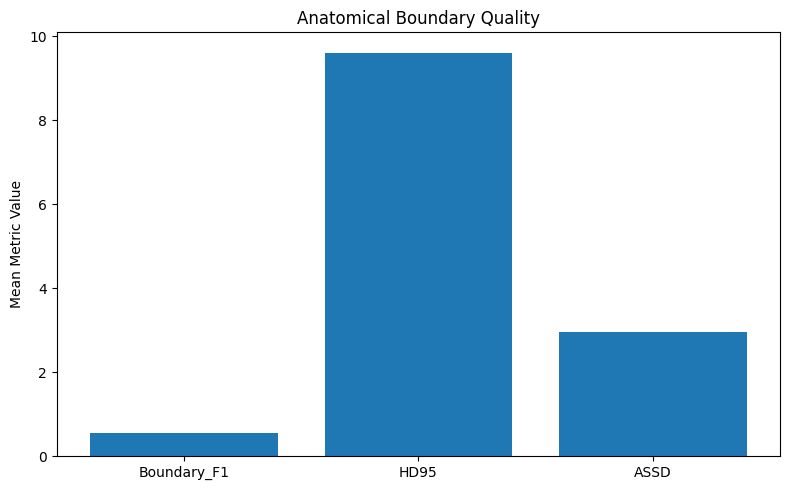

In [98]:
# ============================================================
# NOVELTY 2:
# ANATOMICAL / BOUNDARY QUALITY
# ============================================================

boundary_metrics = [
    "Boundary_F1",
    "HD95",
    "ASSD"
]

fig, ax = plt.subplots(
    figsize=(8, 5)
)

normalized_values = []

for metric in boundary_metrics:

    value = (
        echonet_results[metric]
        .dropna()
        .mean()
    )

    normalized_values.append(
        value
    )

ax.bar(
    boundary_metrics,
    normalized_values
)

ax.set_ylabel(
    "Mean Metric Value"
)

ax.set_title(
    "Anatomical Boundary Quality"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "Novelty2_Anatomical_Boundary_Quality.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()


In [99]:
# ============================================================
# NOVELTY 3:
# TEMPORAL CONSISTENCY / STABILITY
# ============================================================

@torch.no_grad()
def evaluate_temporal_stability(
    model,
    loader
):

    model.eval()

    area_changes = []
    centroid_changes = []

    for batch in loader:

        images = batch["images"].to(
            DEVICE
        )

        masks = batch["masks"].to(
            DEVICE
        )

        predictions, reliability = (
            forward_video(
                model,
                images,
                masks,
                training=False
            )
        )

        probs = torch.sigmoid(
            predictions
        )

        # Skip conditioning frame
        for t in range(2, probs.shape[1]):

            curr = probs[:, t]
            prev = probs[:, t - 1]

            curr_area = soft_area(curr)
            prev_area = soft_area(prev)

            area_change = (
                torch.abs(
                    curr_area -
                    prev_area
                ) /
                (
                    prev_area +
                    EPS
                )
            )

            curr_centroid = (
                soft_centroid(curr)
            )

            prev_centroid = (
                soft_centroid(prev)
            )

            centroid_change = (
                torch.norm(
                    curr_centroid -
                    prev_centroid,
                    dim=-1
                )
            )

            area_changes.extend(
                area_change
                .cpu()
                .numpy()
                .tolist()
            )

            centroid_changes.extend(
                centroid_change
                .cpu()
                .numpy()
                .tolist()
            )

    return (
        np.array(area_changes),
        np.array(centroid_changes)
    )


area_changes, centroid_changes = (
    evaluate_temporal_stability(
        sam2,
        test_loader
    )
)

print(
    "Mean relative area change:",
    area_changes.mean()
)

print(
    "Mean centroid displacement:",
    centroid_changes.mean()
)


Mean relative area change: 0.06521498556578686
Mean centroid displacement: 0.005335452685321798


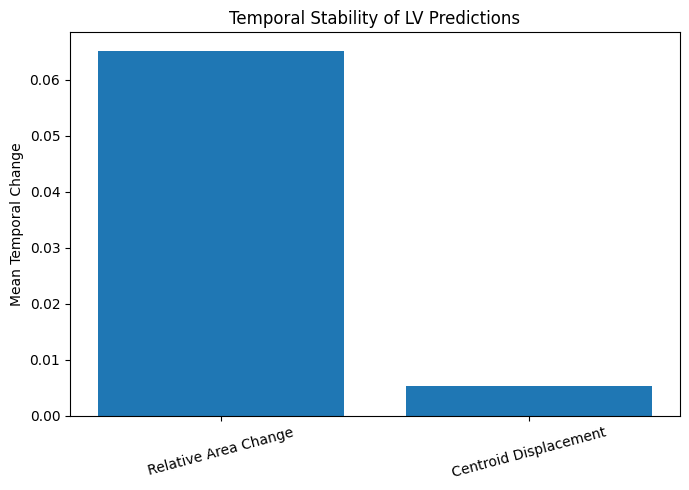

In [100]:
# ============================================================
# TEMPORAL STABILITY FIGURE
# ============================================================

temporal_labels = [
    "Relative Area Change",
    "Centroid Displacement"
]

temporal_values = [
    area_changes.mean(),
    centroid_changes.mean()
]

plt.figure(
    figsize=(7, 5)
)

plt.bar(
    temporal_labels,
    temporal_values
)

plt.ylabel(
    "Mean Temporal Change"
)

plt.title(
    "Temporal Stability of LV Predictions"
)

plt.xticks(
    rotation=15
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVAL_DIR,
        "Novelty3_Temporal_Stability.png"
    ),
    dpi=400,
    bbox_inches="tight"
)

plt.show()


EchoNet-Dynamic Qualitative Evaluation
Only annotated non-conditioning GT frames are displayed


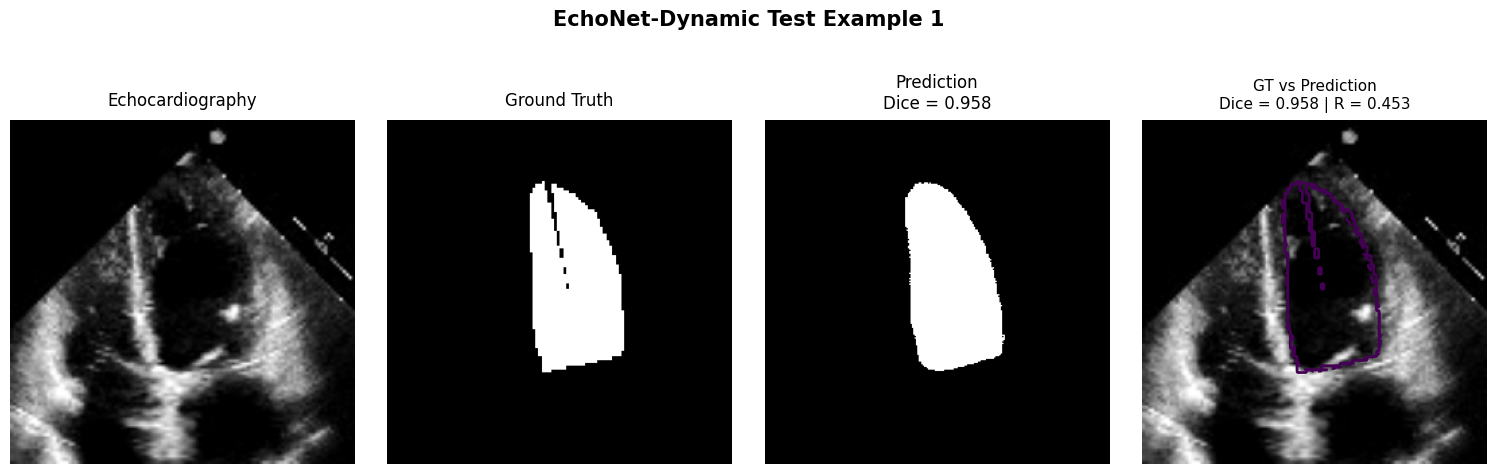


Example 1
Dataset index : 79
Frame         : 7
Dice          : 0.9579
Reliability   : 0.4531
Saved         : /kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_Qualitative_Run1792581969_Example1_Frame7_Dice0.958.png


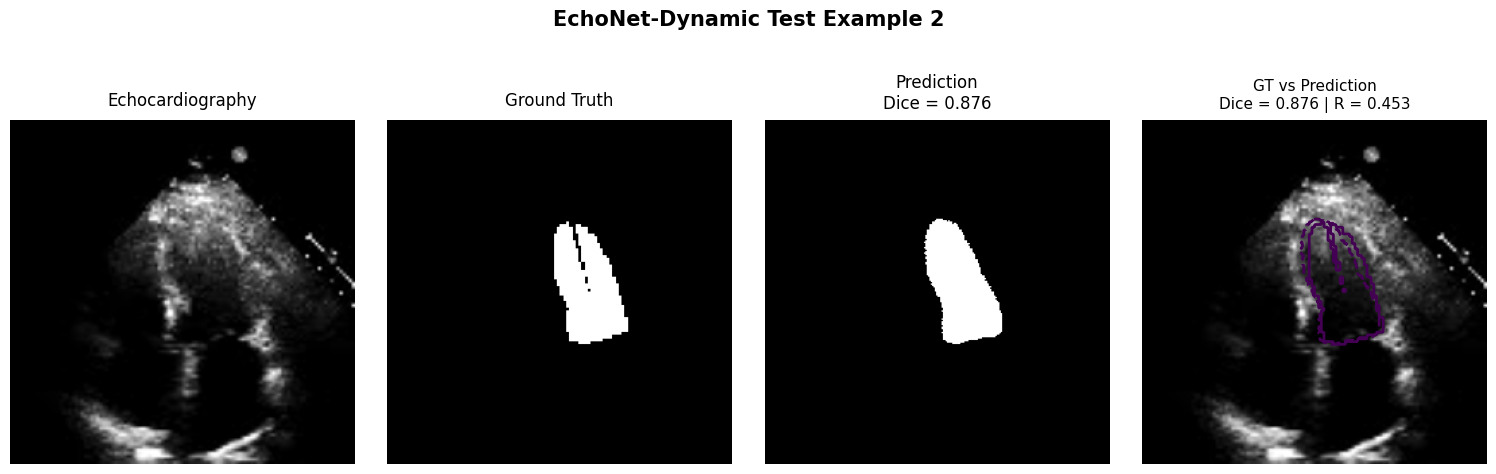


Example 2
Dataset index : 37
Frame         : 7
Dice          : 0.8758
Reliability   : 0.4533
Saved         : /kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_Qualitative_Run1792581969_Example2_Frame7_Dice0.876.png


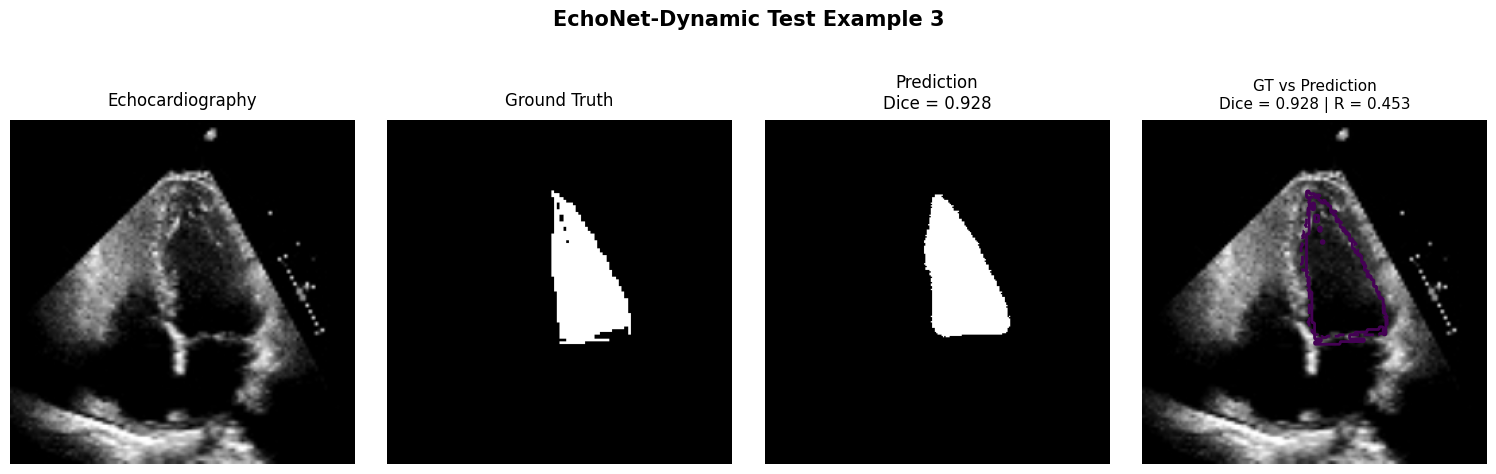


Example 3
Dataset index : 65
Frame         : 7
Dice          : 0.9275
Reliability   : 0.4530
Saved         : /kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_Qualitative_Run1792581969_Example3_Frame7_Dice0.928.png


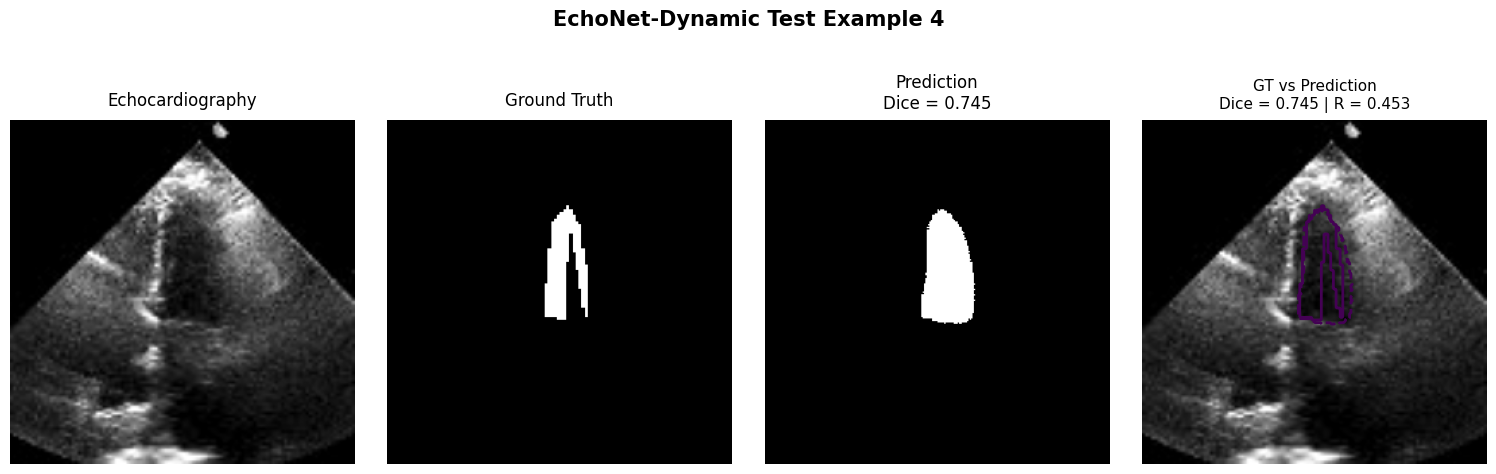


Example 4
Dataset index : 54
Frame         : 7
Dice          : 0.7453
Reliability   : 0.4532
Saved         : /kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_Qualitative_Run1792581969_Example4_Frame7_Dice0.745.png


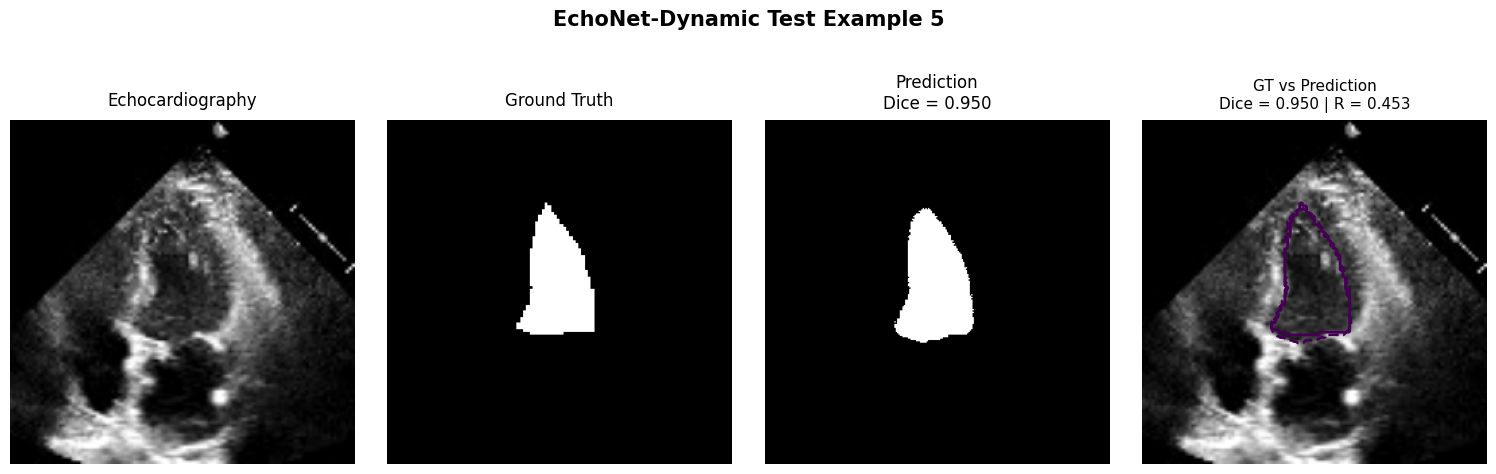


Example 5
Dataset index : 15
Frame         : 7
Dice          : 0.9499
Reliability   : 0.4532
Saved         : /kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_Qualitative_Run1792581969_Example5_Frame7_Dice0.950.png

Generated 5/5 annotated qualitative examples.


In [104]:
# ============================================================
# ECHONET QUALITATIVE RESULTS — CLEAN PUBLICATION VERSION
# ONLY FRAMES WITH AVAILABLE GROUND TRUTH
# RANDOM NEW TEST SAMPLES ON EVERY RUN
# SAVE 400 DPI PNG
# ============================================================

import os
import time
import random
import numpy as np
import torch
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

NUM_EXAMPLES = 5

os.makedirs(EVAL_DIR, exist_ok=True)


# ------------------------------------------------------------
# DICE FOR DISPLAY
# ------------------------------------------------------------

def qualitative_dice(pred, gt, eps=1e-8):

    pred = pred.astype(bool)
    gt = gt.astype(bool)

    intersection = np.logical_and(
        pred,
        gt
    ).sum()

    dice = (
        2.0 * intersection + eps
    ) / (
        pred.sum()
        + gt.sum()
        + eps
    )

    return float(dice)


# ------------------------------------------------------------
# QUALITATIVE FUNCTION
# ------------------------------------------------------------

@torch.no_grad()
def save_qualitative_examples(
    model,
    dataset,
    num_examples=5
):

    model.eval()

    # --------------------------------------------------------
    # RANDOM ORDER
    # New samples on every execution
    # --------------------------------------------------------

    indices = np.random.permutation(
        len(dataset)
    )

    collected = 0

    # Unique run ID so previous figures are not overwritten
    run_id = int(time.time())

    print("=" * 75)
    print("EchoNet-Dynamic Qualitative Evaluation")
    print("Only annotated non-conditioning GT frames are displayed")
    print("=" * 75)


    # ========================================================
    # LOOP THROUGH RANDOM TEST VIDEOS
    # ========================================================

    for dataset_idx in indices:

        if collected >= num_examples:
            break

        # ----------------------------------------------------
        # LOAD RANDOM TEST VIDEO
        # ----------------------------------------------------

        sample = dataset[
            int(dataset_idx)
        ]

        images = (
            sample["images"]
            .unsqueeze(0)
            .to(DEVICE)
        )

        masks = (
            sample["masks"]
            .unsqueeze(0)
            .to(DEVICE)
        )


        # ----------------------------------------------------
        # MODEL PREDICTION
        # ----------------------------------------------------

        predictions, reliability = forward_video(
            model,
            images,
            masks,
            training=False
        )

        probs = torch.sigmoid(
            predictions
        )

        preds = (
            probs > 0.5
        ).float()


        # ----------------------------------------------------
        # FIND ACTUALLY ANNOTATED FRAMES
        # ----------------------------------------------------

        gt_pixel_counts = (
            masks[0]
            .sum(dim=(1, 2, 3))
            .detach()
            .cpu()
            .numpy()
        )

        annotated_frames = np.where(
            gt_pixel_counts > 0
        )[0]


        # ----------------------------------------------------
        # EXCLUDE FRAME 0
        #
        # Frame 0 = conditioning/prompt frame
        # We want propagated segmentation evaluation.
        # ----------------------------------------------------

        evaluation_frames = [
            int(t)
            for t in annotated_frames
            if int(t) != 0
        ]

        if len(evaluation_frames) == 0:
            continue


        # ----------------------------------------------------
        # RANDOM ANNOTATED EVALUATION FRAME
        # ----------------------------------------------------

        t = random.choice(
            evaluation_frames
        )


        # ----------------------------------------------------
        # EXTRACT DATA
        # ----------------------------------------------------

        image = (
            images[0, t, 0]
            .detach()
            .cpu()
            .numpy()
        )

        gt = (
            masks[0, t, 0]
            .detach()
            .cpu()
            .numpy()
            > 0.5
        )

        pred = (
            preds[0, t, 0]
            .detach()
            .cpu()
            .numpy()
            > 0.5
        )


        # ----------------------------------------------------
        # SAFETY CHECK
        # ----------------------------------------------------

        if not gt.any():
            continue


        # ----------------------------------------------------
        # DICE
        # ----------------------------------------------------

        dice = qualitative_dice(
            pred,
            gt
        )

        rel = (
            reliability[0, t]
            .detach()
            .cpu()
            .item()
        )


        # ====================================================
        # CREATE CLEAN PUBLICATION FIGURE
        # ====================================================

        fig, axes = plt.subplots(
            1,
            4,
            figsize=(15.5, 4.6)
        )


        # ----------------------------------------------------
        # PANEL 1 — ECHOCARDIOGRAPHY
        # ----------------------------------------------------

        axes[0].imshow(
            image,
            cmap="gray"
        )

        axes[0].set_title(
            "Echocardiography",
            fontsize=12,
            pad=10
        )


        # ----------------------------------------------------
        # PANEL 2 — GROUND TRUTH
        # ----------------------------------------------------

        axes[1].imshow(
            gt,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[1].set_title(
            "Ground Truth",
            fontsize=12,
            pad=10
        )


        # ----------------------------------------------------
        # PANEL 3 — PREDICTION
        # ----------------------------------------------------

        axes[2].imshow(
            pred,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[2].set_title(
            f"Prediction\nDice = {dice:.3f}",
            fontsize=12,
            pad=8
        )


        # ----------------------------------------------------
        # PANEL 4 — OVERLAY
        # ----------------------------------------------------

        axes[3].imshow(
            image,
            cmap="gray"
        )

        # Ground-truth contour
        if gt.any():

            axes[3].contour(
                gt.astype(float),
                levels=[0.5],
                linewidths=2.0,
                linestyles="-"
            )

        # Prediction contour
        if pred.any():

            axes[3].contour(
                pred.astype(float),
                levels=[0.5],
                linewidths=2.0,
                linestyles="--"
            )

        axes[3].set_title(
            "GT vs Prediction\n"
            f"Dice = {dice:.3f} | R = {rel:.3f}",
            fontsize=11,
            pad=8
        )


        # ----------------------------------------------------
        # REMOVE AXES
        # ----------------------------------------------------

        for ax in axes:

            ax.set_xticks([])
            ax.set_yticks([])

            for spine in ax.spines.values():
                spine.set_visible(False)


        # ====================================================
        # MAIN TITLE
        #
        # y=1.04 moves title ABOVE subplot titles.
        # ====================================================

        fig.suptitle(
            f"EchoNet-Dynamic Test Example {collected + 1}",
            fontsize=15,
            fontweight="bold",
            y=1.04
        )


        # ----------------------------------------------------
        # MANUAL SPACING
        #
        # IMPORTANT:
        # rect reserves upper space for main title.
        # ----------------------------------------------------

        plt.tight_layout(
            rect=[
                0.01,   # left
                0.02,   # bottom
                0.99,   # right
                0.91    # top
            ],
            w_pad=1.5
        )


        # ----------------------------------------------------
        # UNIQUE SAVE PATH
        # ----------------------------------------------------

        save_path = os.path.join(
            EVAL_DIR,
            (
                f"EchoNet_Qualitative_"
                f"Run{run_id}_"
                f"Example{collected + 1}_"
                f"Frame{t}_"
                f"Dice{dice:.3f}.png"
            )
        )


        # ----------------------------------------------------
        # SAVE 400 DPI
        # ----------------------------------------------------

        fig.savefig(
            save_path,
            dpi=400,
            bbox_inches="tight",
            pad_inches=0.15
        )

        plt.show()

        plt.close(fig)


        # ----------------------------------------------------
        # PRINT RESULT
        # ----------------------------------------------------

        print(
            f"\nExample {collected + 1}"
        )

        print(
            f"Dataset index : {dataset_idx}"
        )

        print(
            f"Frame         : {t}"
        )

        print(
            f"Dice          : {dice:.4f}"
        )

        print(
            f"Reliability   : {rel:.4f}"
        )

        print(
            f"Saved         : {save_path}"
        )

        collected += 1


    # ========================================================
    # FINAL STATUS
    # ========================================================

    print("\n" + "=" * 75)

    print(
        f"Generated {collected}/{num_examples} "
        f"annotated qualitative examples."
    )

    if collected < num_examples:

        print(
            "Some examples were skipped because an additional "
            "annotated GT frame was unavailable."
        )

    print("=" * 75)


# ============================================================
# RUN
# ============================================================

save_qualitative_examples(
    sam2,
    test_loader.dataset,
    num_examples=NUM_EXAMPLES
)

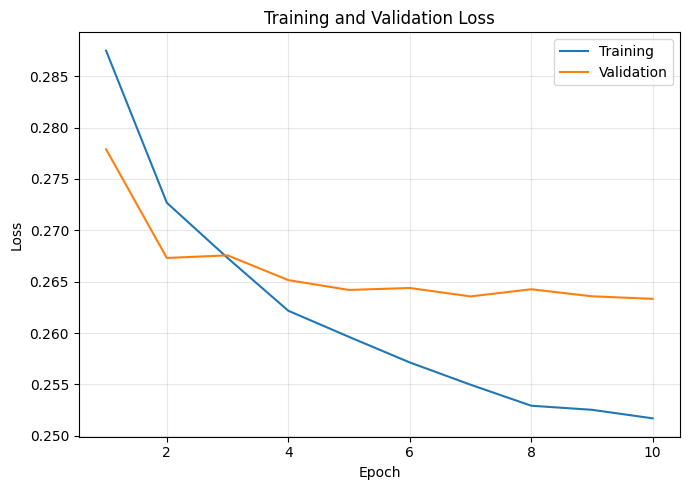

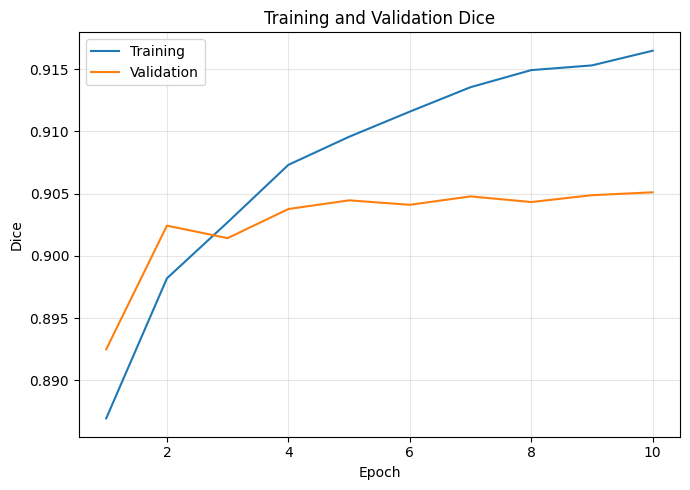

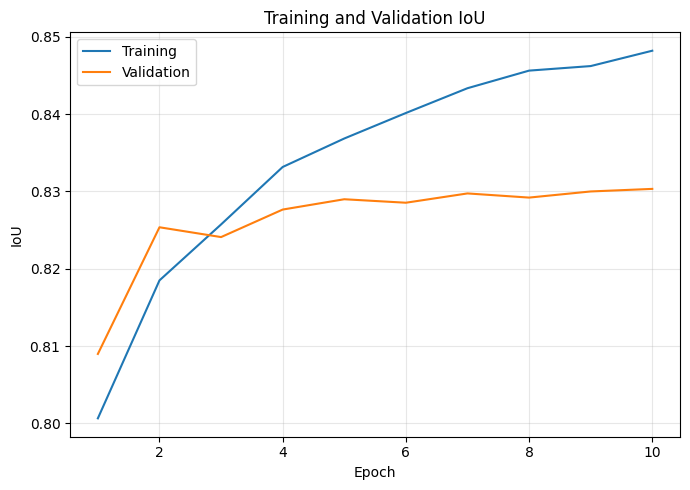

In [105]:
# ============================================================
# SAVE TRAINING CURVES
# ============================================================

epochs = np.arange(
    1,
    len(history["train_loss"]) + 1
)

for metric, ylabel in [
    ("loss", "Loss"),
    ("dice", "Dice"),
    ("iou", "IoU")
]:

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        epochs,
        history[f"train_{metric}"],
        label="Training"
    )

    plt.plot(
        epochs,
        history[f"val_{metric}"],
        label="Validation"
    )

    plt.xlabel("Epoch")
    plt.ylabel(ylabel)

    plt.title(
        f"Training and Validation {ylabel}"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            EVAL_DIR,
            f"Training_{metric.capitalize()}_Curve.png"
        ),
        dpi=400,
        bbox_inches="tight"
    )

    plt.show()


## EchoNet-Dynamic training experiment
The cells below from the original CAMUS→EchoNet external-validation block are intentionally disabled because EchoNet-Dynamic is now the **training domain**. The official EchoNet TEST subset above is the held-out evaluation set. Use a different dataset later for true cross-dataset external validation.


**Disabled legacy cell 60.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 61.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 62.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 63.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 64.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 65.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 66.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 67.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 68.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 69.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 70.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 71.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 72.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 73.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 74.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 75.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 76.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 77.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


**Disabled legacy cell 78.** This belonged to the previous CAMUS-trained → EchoNet zero-shot evaluation and must not be run in the EchoNet-trained experiment.


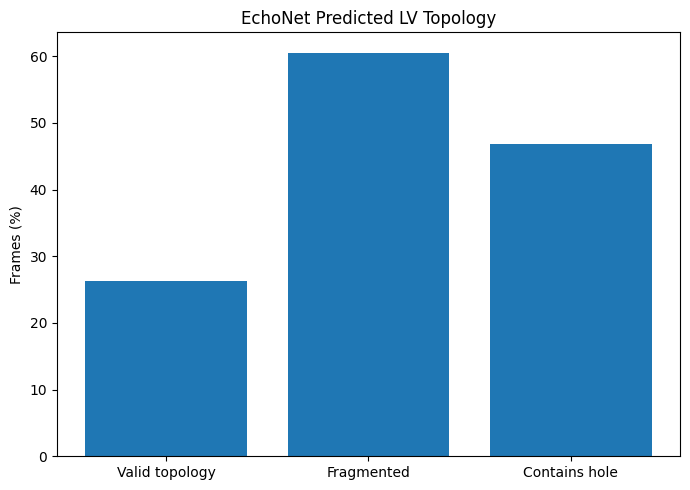

Topology valid %: 26.285714285714285 Fragmented %: 60.57142857142858 Hole %: 46.85714285714286


In [106]:
# ============================================================
# NOVELTY 2 — TOPOLOGY VALIDITY ACROSS PREDICTED VIDEO FRAMES
# ============================================================
from scipy.ndimage import label as cc_label, binary_fill_holes

def binary_topology_stats(mask):
    m=mask.astype(bool)
    if m.sum()==0: return 0,0,0.0
    _,n=cc_label(m); filled=binary_fill_holes(m); holes=int(np.logical_and(filled,~m).any())
    return int(n),holes,float(n==1 and holes==0)

@torch.no_grad()
def evaluate_topology_validity(model,loader):
    model.eval(); rows=[]
    for batch in loader:
        images=batch["images"].to(DEVICE); masks=batch["masks"].to(DEVICE)
        pred,rel=forward_video(model,images,masks,training=False)
        pm=(torch.sigmoid(pred[:,1:])>0.5).cpu().numpy().astype(np.uint8)
        for b in range(pm.shape[0]):
            for t in range(pm.shape[1]):
                pc,ph,pv=binary_topology_stats(pm[b,t,0]); rows.append({"Pred_Components":pc,"Pred_Hole":ph,"Topology_Valid":pv})
    return pd.DataFrame(rows)

topology_results=evaluate_topology_validity(sam2,test_loader)
topology_results.to_csv(os.path.join(EVAL_DIR,"Novelty2_Topology_Results.csv"),index=False)
vals=[topology_results.Topology_Valid.mean()*100,(topology_results.Pred_Components>1).mean()*100,topology_results.Pred_Hole.mean()*100]
plt.figure(figsize=(7,5)); plt.bar(["Valid topology","Fragmented", "Contains hole"],vals); plt.ylabel("Frames (%)"); plt.title("EchoNet Predicted LV Topology"); plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR,"Novelty2_Topology_Validity.png"),dpi=400,bbox_inches="tight"); plt.show()
print("Topology valid %:",vals[0],"Fragmented %:",vals[1],"Hole %:",vals[2])


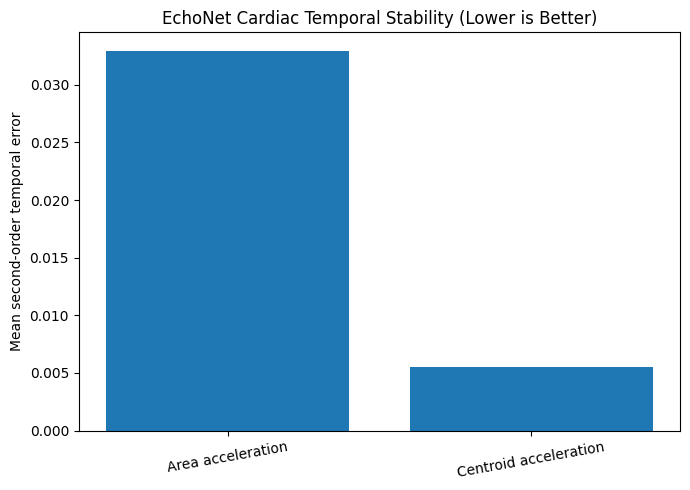

Mean area jitter: 0.03290196085336599
Mean centroid jitter: 0.005520565920208658


In [107]:
# ============================================================
# FULL NOVELTY METRICS: SECOND-ORDER TEMPORAL JITTER
# ============================================================
@torch.no_grad()
def evaluate_temporal_jitter(model, loader):
    model.eval()
    area_jitter, centroid_jitter = [], []
    for batch in loader:
        images = batch["images"].to(DEVICE, non_blocking=True)
        masks = batch["masks"].to(DEVICE, non_blocking=True)
        pred, rel = forward_video(model, images, masks, training=False)
        p = torch.sigmoid(pred)
        for t in range(2, p.shape[1]):
            a0, a1, a2 = soft_area(p[:,t-2]), soft_area(p[:,t-1]), soft_area(p[:,t])
            c0, c1, c2 = soft_centroid(p[:,t-2]), soft_centroid(p[:,t-1]), soft_centroid(p[:,t])
            aj = torch.abs(a2 - 2*a1 + a0) / (a1 + EPS)
            cj = torch.norm(c2 - 2*c1 + c0, dim=-1)
            area_jitter.extend(aj.cpu().numpy().tolist())
            centroid_jitter.extend(cj.cpu().numpy().tolist())
    return np.asarray(area_jitter), np.asarray(centroid_jitter)

area_jitter, centroid_jitter = evaluate_temporal_jitter(sam2, test_loader)
pd.DataFrame({"Area_Jitter":area_jitter,"Centroid_Jitter":centroid_jitter}).to_csv(
    os.path.join(EVAL_DIR, "Novelty3_Temporal_Jitter.csv"), index=False)
plt.figure(figsize=(7,5))
plt.bar(["Area acceleration", "Centroid acceleration"], [area_jitter.mean(), centroid_jitter.mean()])
plt.ylabel("Mean second-order temporal error")
plt.title("EchoNet Cardiac Temporal Stability (Lower is Better)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, "Novelty3_SecondOrder_Temporal_Stability.png"), dpi=400, bbox_inches="tight")
plt.show()
print("Mean area jitter:", float(area_jitter.mean()))
print("Mean centroid jitter:", float(centroid_jitter.mean()))


Reliability min/max/std: 0.452392578125 0.454345703125 0.00021643310820893252
Pearson: -0.3257608229796795
Spearman: -0.06447107137846823


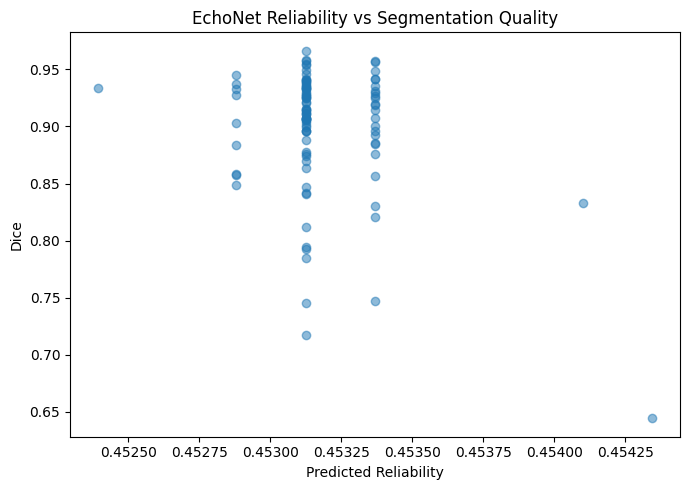

In [108]:
# ============================================================
# NOVELTY 1 — RELIABILITY DIAGNOSTIC (DO NOT FORCE CALIBRATION)
# ============================================================
r=echonet_results["Reliability"].to_numpy(); d=echonet_results["Dice"].to_numpy()
print("Reliability min/max/std:",float(np.min(r)),float(np.max(r)),float(np.std(r)))
if np.unique(np.round(r,8)).size < 2 or np.std(r) < 1e-6:
    print("Reliability is nearly constant; correlation/calibration is not scientifically meaningful.")
else:
    print("Pearson:",pd.Series(r).corr(pd.Series(d),method="pearson"))
    print("Spearman:",pd.Series(r).corr(pd.Series(d),method="spearman"))
    plt.figure(figsize=(7,5)); plt.scatter(r,d,alpha=.5); plt.xlabel("Predicted Reliability"); plt.ylabel("Dice"); plt.title("EchoNet Reliability vs Segmentation Quality"); plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR,"Novelty1_Reliability_vs_Dice.png"),dpi=400,bbox_inches="tight"); plt.show()


In [109]:
# ============================================================
# FINAL EXPERIMENT SANITY CHECK
# ============================================================
print("EchoNet-Dynamic experiment configuration:")
print("  TRAIN/VAL/TEST:",len(train_dataset),len(val_dataset),len(test_dataset))
print("  EF-balanced subset selection: YES")
print("  Official split separation: YES")
print("  Sequence length:",SEQ_LEN)
print("  First traced frame used only as SAM2 conditioning prompt: YES")
print("  Last traced frame used as supervised target: YES")
print("  Reliability-guided SAM2 memory gating: YES")
print("  Topology-aware objective: YES")
print("  Second-order temporal consistency: YES")
print("  Same SAM2.1 Hiera-Tiny backbone / LR / loss weights / epochs as CAMUS notebook: YES")


EchoNet-Dynamic experiment configuration:
  TRAIN/VAL/TEST: 300 50 100
  EF-balanced subset selection: YES
  Official split separation: YES
  Sequence length: 8
  First traced frame used only as SAM2 conditioning prompt: YES
  Last traced frame used as supervised target: YES
  Reliability-guided SAM2 memory gating: YES
  Topology-aware objective: YES
  Second-order temporal consistency: YES
  Same SAM2.1 Hiera-Tiny backbone / LR / loss weights / epochs as CAMUS notebook: YES


In [110]:
# ============================================================
# CROSS-DATASET VALIDATION
# TRAIN: ECHONET-DYNAMIC
# EXTERNAL TEST: CAMUS 4CH
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import nibabel as nib
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader


# ------------------------------------------------------------
# CAMUS PATH
# ------------------------------------------------------------

CAMUS_ROOT = (
    "/kaggle/input/datasets/mykcs01/"
    "camus-public-20250702/CAMUS_public"
)

CAMUS_NIFTI_DIR = os.path.join(
    CAMUS_ROOT,
    "database_nifti"
)

print("CAMUS root:", CAMUS_ROOT)
print("CAMUS NIfTI:", CAMUS_NIFTI_DIR)

assert os.path.exists(
    CAMUS_NIFTI_DIR
), "CAMUS database_nifti folder not found."


# ------------------------------------------------------------
# CROSS-DATASET SETTINGS
# ------------------------------------------------------------

CAMUS_IMAGE_SIZE = 256
CAMUS_SEQUENCE_LENGTH = 8

# Keep external evaluation manageable
CAMUS_EXTERNAL_PATIENTS = 100

CAMUS_EXTERNAL_SEED = 42

CROSS_DIR = os.path.join(
    EVAL_DIR,
    "EchoNet_to_CAMUS"
)

os.makedirs(
    CROSS_DIR,
    exist_ok=True
)

print("Cross-validation output:")
print(CROSS_DIR)

CAMUS root: /kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public
CAMUS NIfTI: /kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti
Cross-validation output:
/kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_to_CAMUS


In [111]:
# ============================================================
# FIND CAMUS PATIENTS WITH 4CH SEQUENCES
# ============================================================

patient_dirs = sorted(
    glob.glob(
        os.path.join(
            CAMUS_NIFTI_DIR,
            "patient*"
        )
    )
)

valid_camus_patients = []

for patient_dir in patient_dirs:

    patient_id = os.path.basename(
        patient_dir
    )

    image_path = os.path.join(
        patient_dir,
        f"{patient_id}_4CH_half_sequence.nii.gz"
    )

    mask_path = os.path.join(
        patient_dir,
        f"{patient_id}_4CH_half_sequence_gt.nii.gz"
    )

    if (
        os.path.exists(image_path)
        and os.path.exists(mask_path)
    ):

        valid_camus_patients.append(
            patient_id
        )


print(
    "Total CAMUS 4CH patients available:",
    len(valid_camus_patients)
)


# ------------------------------------------------------------
# DETERMINISTIC EXTERNAL SUBSET
# ------------------------------------------------------------

rng = np.random.default_rng(
    CAMUS_EXTERNAL_SEED
)

num_external = min(
    CAMUS_EXTERNAL_PATIENTS,
    len(valid_camus_patients)
)

selected_camus_patients = sorted(
    rng.choice(
        valid_camus_patients,
        size=num_external,
        replace=False
    ).tolist()
)

print(
    "CAMUS external patients selected:",
    len(selected_camus_patients)
)

print(
    "Seed:",
    CAMUS_EXTERNAL_SEED
)

print(
    "First patients:",
    selected_camus_patients[:10]
)

Total CAMUS 4CH patients available: 0
CAMUS external patients selected: 0
Seed: 42
First patients: []


In [117]:
# ============================================================
# CAMUS EXTERNAL DATASET
# LV CAVITY ONLY
# 4CH ONLY
# ============================================================

class CAMUSExternalDataset(Dataset):

    def __init__(
        self,
        patient_ids,
        nifti_dir,
        image_size=256,
        sequence_length=8
    ):

        self.patient_ids = patient_ids
        self.nifti_dir = nifti_dir
        self.image_size = image_size
        self.sequence_length = sequence_length


    def __len__(self):

        return len(
            self.patient_ids
        )


    def __getitem__(
        self,
        idx
    ):

        patient_id = self.patient_ids[
            idx
        ]

        patient_dir = os.path.join(
            self.nifti_dir,
            patient_id
        )

        image_path = os.path.join(
            patient_dir,
            f"{patient_id}_4CH_half_sequence.nii.gz"
        )

        mask_path = os.path.join(
            patient_dir,
            f"{patient_id}_4CH_half_sequence_gt.nii.gz"
        )


        # ----------------------------------------------------
        # LOAD
        # ----------------------------------------------------

        image = nib.load(
            image_path
        ).get_fdata()

        mask = nib.load(
            mask_path
        ).get_fdata()


        # Expected:
        # H x W x T
        if image.ndim != 3:

            raise ValueError(
                f"Unexpected image shape "
                f"{image.shape} for {patient_id}"
            )

        if mask.ndim != 3:

            raise ValueError(
                f"Unexpected mask shape "
                f"{mask.shape} for {patient_id}"
            )


        total_frames = min(
            image.shape[-1],
            mask.shape[-1]
        )


        # ----------------------------------------------------
        # TEMPORAL SAMPLING
        # ----------------------------------------------------

        if total_frames >= self.sequence_length:

            frame_indices = np.linspace(
                0,
                total_frames - 1,
                self.sequence_length,
                dtype=int
            )

        else:

            frame_indices = np.linspace(
                0,
                total_frames - 1,
                self.sequence_length
            )

            frame_indices = np.round(
                frame_indices
            ).astype(int)


        image = image[
            :, :, frame_indices
        ]

        mask = mask[
            :, :, frame_indices
        ]


        # ----------------------------------------------------
        # MOVE TIME FIRST
        # T x H x W
        # ----------------------------------------------------

        image = np.transpose(
            image,
            (2, 0, 1)
        )

        mask = np.transpose(
            mask,
            (2, 0, 1)
        )


        # ----------------------------------------------------
        # ROBUST NORMALIZATION
        # ----------------------------------------------------

        image = image.astype(
            np.float32
        )

        normalized_frames = []

        for frame in image:

            low = np.percentile(
                frame,
                1
            )

            high = np.percentile(
                frame,
                99
            )

            if high > low:

                frame = np.clip(
                    frame,
                    low,
                    high
                )

                frame = (
                    frame - low
                ) / (
                    high - low + 1e-8
                )

            else:

                frame = np.zeros_like(
                    frame
                )

            normalized_frames.append(
                frame
            )


        image = np.stack(
            normalized_frames,
            axis=0
        )


        # ----------------------------------------------------
        # CAMUS LV CAVITY = LABEL 1
        # ----------------------------------------------------

        mask = (
            mask == 1
        ).astype(
            np.float32
        )


        # ----------------------------------------------------
        # TO TENSORS
        # ----------------------------------------------------

        image = torch.from_numpy(
            image
        ).float().unsqueeze(1)

        mask = torch.from_numpy(
            mask
        ).float().unsqueeze(1)


        # ----------------------------------------------------
        # RESIZE TO 256 x 256
        # ----------------------------------------------------

        image = F.interpolate(
            image,
            size=(
                self.image_size,
                self.image_size
            ),
            mode="bilinear",
            align_corners=False
        )

        mask = F.interpolate(
            mask,
            size=(
                self.image_size,
                self.image_size
            ),
            mode="nearest"
        )


        # ----------------------------------------------------
        # GRAYSCALE -> RGB
        #
        # T x 1 x H x W
        # ->
        # T x 3 x H x W
        # ----------------------------------------------------

        image = image.repeat(
            1,
            3,
            1,
            1
        )


        return {

            "images": image,

            "masks": mask,

            "patient_id": patient_id,

            "frame_indices": torch.tensor(
                frame_indices,
                dtype=torch.long
            )
        }

In [119]:
# ============================================================
# FIND ACTUAL CAMUS FILE STRUCTURE
# ============================================================

import os
import glob

CAMUS_ROOT = (
    "/kaggle/input/datasets/mykcs01/"
    "camus-public-20250702/CAMUS_public"
)

CAMUS_NIFTI_DIR = os.path.join(
    CAMUS_ROOT,
    "database_nifti"
)

print("=" * 70)
print("CAMUS PATH CHECK")
print("=" * 70)

print("Root exists:", os.path.exists(CAMUS_ROOT))
print("NIfTI exists:", os.path.exists(CAMUS_NIFTI_DIR))
print("Path:", CAMUS_NIFTI_DIR)

print("\nTop-level contents:")

items = glob.glob(
    os.path.join(CAMUS_NIFTI_DIR, "*")
)

print("Number of items:", len(items))

for x in items[:20]:
    print(x)


print("\nSearching recursively for 4CH sequences...")

all_4ch = glob.glob(
    os.path.join(
        CAMUS_NIFTI_DIR,
        "**",
        "*4CH*"
    ),
    recursive=True
)

print("4CH files found:", len(all_4ch))

for x in all_4ch[:30]:
    print(x)

CAMUS PATH CHECK
Root exists: True
NIfTI exists: True
Path: /kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti

Top-level contents:
Number of items: 501
/kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti/LICENSE_TERMS.md
/kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti/patient0001
/kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti/patient0002
/kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti/patient0003
/kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti/patient0004
/kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti/patient0005
/kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti/patient0006
/kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti/patient0007
/kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/da

In [120]:
# ============================================================
# CHECK EXACT CAMUS FILENAMES
# ============================================================

import os

patient_dir = (
    "/kaggle/input/datasets/mykcs01/"
    "camus-public-20250702/CAMUS_public/"
    "database_nifti/patient0001"
)

files = sorted(os.listdir(patient_dir))

print("Files in patient0001:")
print("=" * 70)

for f in files:
    print(f)

Files in patient0001:
Info_2CH.cfg
Info_4CH.cfg
MANDATORY_CITATION.md
patient0001_2CH_ED.nii
patient0001_2CH_ED_gt.nii
patient0001_2CH_ES.nii
patient0001_2CH_ES_gt.nii
patient0001_2CH_half_sequence.nii
patient0001_2CH_half_sequence_gt.nii
patient0001_4CH_ED.nii
patient0001_4CH_ED_gt.nii
patient0001_4CH_ES.nii
patient0001_4CH_ES_gt.nii
patient0001_4CH_half_sequence.nii
patient0001_4CH_half_sequence_gt.nii


In [126]:
# ============================================================
# CELL 1 — DISCOVER CAMUS 4CH SEQUENCES
# ECHONET -> CAMUS EXTERNAL VALIDATION
# ============================================================

import os
import glob
import numpy as np

CAMUS_NIFTI_DIR = (
    "/kaggle/input/datasets/mykcs01/"
    "camus-public-20250702/CAMUS_public/"
    "database_nifti"
)

CAMUS_EXTERNAL_PATIENTS = 100
CAMUS_EXTERNAL_SEED = 42

assert os.path.exists(CAMUS_NIFTI_DIR)

patient_dirs = sorted([
    p for p in glob.glob(
        os.path.join(CAMUS_NIFTI_DIR, "patient*")
    )
    if os.path.isdir(p)
])

print("Patient folders found:", len(patient_dirs))

valid_camus_samples = []

for patient_dir in patient_dirs:

    patient_id = os.path.basename(patient_dir)

    # Find sequence image
    image_candidates = (
        glob.glob(
            os.path.join(
                patient_dir,
                f"{patient_id}_4CH_half_sequence.nii"
            )
        )
        +
        glob.glob(
            os.path.join(
                patient_dir,
                f"{patient_id}_4CH_half_sequence.nii.gz"
            )
        )
    )

    # Find sequence GT
    mask_candidates = (
        glob.glob(
            os.path.join(
                patient_dir,
                f"{patient_id}_4CH_half_sequence_gt.nii"
            )
        )
        +
        glob.glob(
            os.path.join(
                patient_dir,
                f"{patient_id}_4CH_half_sequence_gt.nii.gz"
            )
        )
    )

    if image_candidates and mask_candidates:

        valid_camus_samples.append({
            "patient_id": patient_id,
            "image_path": image_candidates[0],
            "mask_path": mask_candidates[0]
        })


print("Valid CAMUS 4CH sequences:", len(valid_camus_samples))

if len(valid_camus_samples) == 0:

    print("\nFiles inside patient0001:")

    example_dir = os.path.join(
        CAMUS_NIFTI_DIR,
        "patient0001"
    )

    for f in sorted(os.listdir(example_dir)):
        print(f)

    raise RuntimeError(
        "No 4CH half_sequence files detected. "
        "Send me the patient0001 filenames printed above."
    )


# ------------------------------------------------------------
# SELECT 100 DETERMINISTIC EXTERNAL PATIENTS
# ------------------------------------------------------------

rng = np.random.default_rng(
    CAMUS_EXTERNAL_SEED
)

n_select = min(
    CAMUS_EXTERNAL_PATIENTS,
    len(valid_camus_samples)
)

selected_indices = rng.choice(
    len(valid_camus_samples),
    size=n_select,
    replace=False
)

selected_camus_samples = [
    valid_camus_samples[int(i)]
    for i in selected_indices
]


print("\nSelected CAMUS patients:", len(selected_camus_samples))
print("Seed:", CAMUS_EXTERNAL_SEED)

print("\nExample patient:")
print(selected_camus_samples[0])

Patient folders found: 500
Valid CAMUS 4CH sequences: 500

Selected CAMUS patients: 100
Seed: 42

Example patient:
{'patient_id': 'patient0482', 'image_path': '/kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti/patient0482/patient0482_4CH_half_sequence.nii', 'mask_path': '/kaggle/input/datasets/mykcs01/camus-public-20250702/CAMUS_public/database_nifti/patient0482/patient0482_4CH_half_sequence_gt.nii'}


In [134]:
# ============================================================
# CELL 2 — CAMUS EXTERNAL DATASET
# 4CH + LV CAVITY ONLY
# ============================================================

import nibabel as nib
import torch
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader


class CAMUSExternalDataset(Dataset):

    def __init__(
        self,
        samples,
        image_size=256,
        sequence_length=8
    ):

        self.samples = samples
        self.image_size = image_size
        self.sequence_length = sequence_length


    def __len__(self):

        return len(self.samples)


    def __getitem__(self, idx):

        info = self.samples[idx]

        patient_id = info["patient_id"]

        image = nib.load(
            info["image_path"]
        ).get_fdata()

        mask = nib.load(
            info["mask_path"]
        ).get_fdata()


        # ----------------------------------------------------
        # CHECK DIMENSIONS
        # ----------------------------------------------------

        if image.ndim != 3:
            raise ValueError(
                f"{patient_id}: image shape {image.shape}"
            )

        if mask.ndim != 3:
            raise ValueError(
                f"{patient_id}: mask shape {mask.shape}"
            )


        total_frames = min(
            image.shape[-1],
            mask.shape[-1]
        )


        # ----------------------------------------------------
        # SELECT 8 FRAMES ACROSS VIDEO
        # ----------------------------------------------------

        frame_indices = np.linspace(
            0,
            total_frames - 1,
            self.sequence_length
        )

        frame_indices = np.round(
            frame_indices
        ).astype(int)


        image = image[:, :, frame_indices]
        mask = mask[:, :, frame_indices]


        # H,W,T -> T,H,W

        image = np.transpose(
            image,
            (2, 0, 1)
        )

        mask = np.transpose(
            mask,
            (2, 0, 1)
        )


        # ----------------------------------------------------
        # NORMALIZE EACH FRAME
        # ----------------------------------------------------

        processed = []

        for frame in image:

            frame = frame.astype(np.float32)

            low = np.percentile(frame, 1)
            high = np.percentile(frame, 99)

            if high > low:

                frame = np.clip(
                    frame,
                    low,
                    high
                )

                frame = (
                    frame - low
                ) / (
                    high - low + 1e-8
                )

            else:

                frame = np.zeros_like(frame)

            processed.append(frame)


        image = np.stack(
            processed,
            axis=0
        )


        # ----------------------------------------------------
        # COMMON TARGET:
        # CAMUS LV CAVITY = LABEL 1
        # ----------------------------------------------------

        mask = (
            mask == 1
        ).astype(np.float32)


        # ----------------------------------------------------
        # NUMPY -> TORCH
        # ----------------------------------------------------

        image = torch.from_numpy(
            image
        ).float().unsqueeze(1)

        mask = torch.from_numpy(
            mask
        ).float().unsqueeze(1)


        # ----------------------------------------------------
        # RESIZE
        # ----------------------------------------------------

        image = F.interpolate(
            image,
            size=(256, 256),
            mode="bilinear",
            align_corners=False
        )

        mask = F.interpolate(
            mask,
            size=(256, 256),
            mode="nearest"
        )


        # Grayscale -> RGB
        image = image.repeat(
            1,
            3,
            1,
            1
        )


        return {
            "images": image,
            "masks": mask,
            "patient_id": patient_id,
            "frame_indices": torch.tensor(
                frame_indices,
                dtype=torch.long
            )
        }

In [135]:
# ============================================================
# CELL 3 — CAMUS EXTERNAL LOADER + SANITY CHECK
# ============================================================

camus_external_dataset = CAMUSExternalDataset(
    samples=selected_camus_samples,
    image_size=256,
    sequence_length=8
)

camus_external_loader = DataLoader(
    camus_external_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(
    "CAMUS external dataset:",
    len(camus_external_dataset)
)

assert len(camus_external_dataset) > 0


sample = next(
    iter(camus_external_loader)
)

print("\nSANITY CHECK")
print("=" * 60)

print(
    "Images:",
    sample["images"].shape
)

print(
    "Masks:",
    sample["masks"].shape
)

print(
    "Patient:",
    sample["patient_id"][0]
)

print(
    "Frame indices:",
    sample["frame_indices"]
)

print(
    "Mask values:",
    torch.unique(sample["masks"])
)

print(
    "GT pixels per frame:",
    sample["masks"].sum(
        dim=(2, 3, 4)
    )
)

CAMUS external dataset: 100

SANITY CHECK
Images: torch.Size([1, 8, 3, 256, 256])
Masks: torch.Size([1, 8, 1, 256, 256])
Patient: patient0482
Frame indices: tensor([[ 0,  2,  4,  6,  9, 11, 13, 15]])
Mask values: tensor([0., 1.])
GT pixels per frame: tensor([[6695., 6310., 5936., 5562., 5010., 4676., 4344., 4019.]])


In [136]:
# ============================================================
# CELL 4 — ECHONET-TRAINED MODEL -> CAMUS INFERENCE
# NO FUTURE GT LEAKAGE
# ============================================================

@torch.no_grad()
def predict_camus_external(
    model,
    images,
    masks
):

    model.eval()

    # Only first frame used as conditioning mask
    prompt_masks = torch.zeros_like(
        masks
    )

    prompt_masks[:, 0] = masks[:, 0]


    predictions, reliability = forward_video(
        model,
        images,
        prompt_masks,
        training=False
    )

    return predictions, reliability


print(
    "✓ CAMUS external inference function ready"
)

✓ CAMUS external inference function ready


In [137]:
# ============================================================
# CELL 5 — ONE-PATIENT CROSS-DATASET TEST
# ============================================================

batch = next(
    iter(camus_external_loader)
)

images = batch[
    "images"
].to(DEVICE)

masks = batch[
    "masks"
].to(DEVICE)


with torch.no_grad():

    predictions, reliability = (
        predict_camus_external(
            sam2,
            images,
            masks
        )
    )


print("=" * 60)
print("ONE-PATIENT TEST")
print("=" * 60)

print(
    "Images:",
    images.shape
)

print(
    "GT masks:",
    masks.shape
)

print(
    "Predictions:",
    predictions.shape
)

print(
    "Reliability:",
    reliability.shape
)

print(
    "Prediction finite:",
    torch.isfinite(predictions).all().item()
)

print(
    "✓ EchoNet-trained model successfully ran on CAMUS"
)

ONE-PATIENT TEST
Images: torch.Size([1, 8, 3, 256, 256])
GT masks: torch.Size([1, 8, 1, 256, 256])
Predictions: torch.Size([1, 8, 1, 256, 256])
Reliability: torch.Size([1, 8])
Prediction finite: True
✓ EchoNet-trained model successfully ran on CAMUS


In [138]:
# ============================================================
# CELL 6 — FULL CROSS-DATASET VALIDATION
# TRAIN: ECHONET-DYNAMIC
# TEST: CAMUS 4CH
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

CROSS_DIR = os.path.join(
    EVAL_DIR,
    "EchoNet_to_CAMUS"
)

os.makedirs(
    CROSS_DIR,
    exist_ok=True
)


@torch.no_grad()
def evaluate_echonet_to_camus(
    model,
    loader,
    device
):

    model.eval()

    rows = []

    print("=" * 75)
    print("CROSS-DATASET EXTERNAL VALIDATION")
    print("TRAINED ON : EchoNet-Dynamic")
    print("TESTED ON  : CAMUS 4CH")
    print("=" * 75)

    for batch_idx, batch in enumerate(loader):

        images = batch[
            "images"
        ].to(
            device,
            non_blocking=True
        )

        masks = batch[
            "masks"
        ].to(
            device,
            non_blocking=True
        )

        patient_id = batch[
            "patient_id"
        ][0]

        frame_indices = (
            batch["frame_indices"][0]
            .detach()
            .cpu()
            .numpy()
        )


        # ----------------------------------------------------
        # PREDICT
        # ONLY FRAME 0 GT IS USED AS CONDITIONING
        # ----------------------------------------------------

        predictions, reliability = (
            predict_camus_external(
                model,
                images,
                masks
            )
        )

        probs = torch.sigmoid(
            predictions
        )

        preds = (
            probs > 0.5
        ).float()


        # ----------------------------------------------------
        # FRAME 0 IS CONDITIONING FRAME
        # DO NOT INCLUDE IT IN TEST RESULTS
        # ----------------------------------------------------

        for t in range(
            1,
            images.shape[1]
        ):

            gt = (
                masks[0, t, 0]
                .detach()
                .cpu()
                .numpy()
                > 0.5
            )

            pred = (
                preds[0, t, 0]
                .detach()
                .cpu()
                .numpy()
                > 0.5
            )


            # ------------------------------------------------
            # SEGMENTATION METRICS
            # ------------------------------------------------

            metrics = calculate_binary_metrics(
                pred.astype(np.float32),
                gt.astype(np.float32)
            )


            # ------------------------------------------------
            # SURFACE METRICS
            # ------------------------------------------------

            hd95, assd = surface_distances(
                pred,
                gt
            )


            # ------------------------------------------------
            # BOUNDARY F1
            # ------------------------------------------------

            bf1 = boundary_f1(
                pred,
                gt
            )


            # ------------------------------------------------
            # RELIABILITY
            # ------------------------------------------------

            rel = (
                reliability[0, t]
                .detach()
                .cpu()
                .item()
            )


            # ------------------------------------------------
            # STORE
            # ------------------------------------------------

            rows.append({

                "Training_Dataset":
                    "EchoNet-Dynamic",

                "Test_Dataset":
                    "CAMUS_4CH",

                "Patient":
                    patient_id,

                "Sequence_Frame":
                    int(t),

                "Original_Frame":
                    int(frame_indices[t]),

                "Dice":
                    metrics["Dice"],

                "IoU":
                    metrics["IoU"],

                "Precision":
                    metrics["Precision"],

                "Recall":
                    metrics["Recall"],

                "Specificity":
                    metrics["Specificity"],

                "F1":
                    metrics["F1"],

                "Accuracy":
                    metrics["Accuracy"],

                "HD95":
                    hd95,

                "ASSD":
                    assd,

                "Boundary_F1":
                    bf1,

                "Reliability":
                    rel
            })


        # ----------------------------------------------------
        # PROGRESS
        # ----------------------------------------------------

        if (
            (batch_idx + 1) % 10 == 0
            or (batch_idx + 1) == len(loader)
        ):

            print(
                f"Processed "
                f"{batch_idx + 1}/"
                f"{len(loader)} CAMUS patients"
            )


    results = pd.DataFrame(
        rows
    )

    return results


# ============================================================
# RUN
# ============================================================

camus_cross_results = evaluate_echonet_to_camus(
    sam2,
    camus_external_loader,
    DEVICE
)


print("\n" + "=" * 75)

print(
    "Total CAMUS patients:",
    camus_cross_results[
        "Patient"
    ].nunique()
)

print(
    "Total evaluated frames:",
    len(camus_cross_results)
)

print("=" * 75)


display(
    camus_cross_results.head(10)
)


# ------------------------------------------------------------
# SAVE FRAME-LEVEL RESULTS
# ------------------------------------------------------------

frame_results_path = os.path.join(
    CROSS_DIR,
    "EchoNet_to_CAMUS_Frame_Level_Results.csv"
)

camus_cross_results.to_csv(
    frame_results_path,
    index=False
)

print("\n✓ Saved:")
print(frame_results_path)

CROSS-DATASET EXTERNAL VALIDATION
TRAINED ON : EchoNet-Dynamic
TESTED ON  : CAMUS 4CH
Processed 10/100 CAMUS patients
Processed 20/100 CAMUS patients
Processed 30/100 CAMUS patients
Processed 40/100 CAMUS patients
Processed 50/100 CAMUS patients
Processed 60/100 CAMUS patients
Processed 70/100 CAMUS patients
Processed 80/100 CAMUS patients
Processed 90/100 CAMUS patients
Processed 100/100 CAMUS patients

Total CAMUS patients: 100
Total evaluated frames: 700


,Training_Dataset,Test_Dataset,Patient,Sequence_Frame,Original_Frame,Dice,IoU,Precision,Recall,Specificity,F1,Accuracy,HD95,ASSD,Boundary_F1,Reliability
0,EchoNet-Dynamic,CAMUS_4CH,patient0482,1,2,0.978101,0.957141,0.986617,0.969731,0.998599,0.978101,0.995819,2.000000,0.775723,0.954558,0.453044
1,EchoNet-Dynamic,CAMUS_4CH,patient0482,2,4,0.955819,0.915377,0.975781,0.936658,0.997685,0.955819,0.992157,3.605551,1.492693,0.805419,0.453002
2,EchoNet-Dynamic,CAMUS_4CH,patient0482,3,6,0.944836,0.895440,0.961818,0.928443,0.996582,0.944836,0.990799,5.000000,1.774742,0.722582,0.452987
3,EchoNet-Dynamic,CAMUS_4CH,patient0482,4,9,0.936901,0.881292,0.947906,0.926148,0.995787,0.936901,0.990463,5.830952,1.945109,0.649366,0.453196
4,EchoNet-Dynamic,CAMUS_4CH,patient0482,5,11,0.918849,0.849880,0.926135,0.911677,0.994413,0.918849,0.988510,6.340269,2.321692,0.564501,0.452940
5,EchoNet-Dynamic,CAMUS_4CH,patient0482,6,13,0.913133,0.840151,0.904472,0.921961,0.993087,0.913133,0.988373,6.000000,2.341952,0.494006,0.453214
6,EchoNet-Dynamic,CAMUS_4CH,patient0482,7,15,0.900192,0.818499,0.869122,0.933566,0.990816,0.900192,0.987305,5.830952,2.672583,0.460627,0.453078
7,EchoNet-Dynamic,CAMUS_4CH,patient0453,1,2,0.957774,0.918969,0.987314,0.929950,0.998068,0.957774,0.988586,5.000000,1.799975,0.710567,0.452908
8,EchoNet-Dynamic,CAMUS_4CH,patient0453,2,4,0.942472,0.891203,0.992870,0.896943,0.999035,0.942472,0.985733,7.280110,2.304793,0.654529,0.452944
9,EchoNet-Dynamic,CAMUS_4CH,patient0453,3,6,0.936062,0.879808,0.981492,0.894651,0.997654,0.936062,0.985077,8.000000,2.449581,0.596674,0.452916



✓ Saved:
/kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_to_CAMUS/EchoNet_to_CAMUS_Frame_Level_Results.csv


In [139]:
# ============================================================
# CELL 7 — CROSS-DATASET SUMMARY TABLE
# ECHONET-DYNAMIC -> CAMUS
# ============================================================

metric_columns = [
    "Dice",
    "IoU",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "Accuracy",
    "HD95",
    "ASSD",
    "Boundary_F1",
    "Reliability"
]


summary_rows = []


for metric in metric_columns:

    values = pd.to_numeric(
        camus_cross_results[metric],
        errors="coerce"
    )

    values = values.replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna()

    summary_rows.append({

        "Metric":
            metric,

        "Mean":
            values.mean(),

        "SD":
            values.std(),

        "Median":
            values.median(),

        "Min":
            values.min(),

        "Max":
            values.max(),

        "N":
            len(values)
    })


camus_cross_summary = pd.DataFrame(
    summary_rows
)


print("\n" + "=" * 85)
print(
    "ECHONET-DYNAMIC -> CAMUS "
    "CROSS-DATASET EXTERNAL VALIDATION"
)
print("=" * 85)

display(
    camus_cross_summary.round(4)
)


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

summary_path = os.path.join(
    CROSS_DIR,
    "EchoNet_to_CAMUS_Summary.csv"
)

camus_cross_summary.to_csv(
    summary_path,
    index=False
)

print("\n✓ Saved:")
print(summary_path)


ECHONET-DYNAMIC -> CAMUS CROSS-DATASET EXTERNAL VALIDATION


,Metric,Mean,SD,Median,Min,Max,N
0,Dice,0.9300,0.0409,0.9372,0.6756,0.9856,700
1,IoU,0.8717,0.0669,0.8817,0.5102,0.9716,700
2,Precision,0.9327,0.0527,0.9450,0.6854,1.0000,700
3,Recall,0.9318,0.0636,0.9493,0.6141,0.9991,700
4,Specificity,0.9941,0.0044,0.9951,0.9719,1.0000,700
5,F1,0.9300,0.0409,0.9372,0.6756,0.9856,700
6,Accuracy,0.9882,0.0079,0.9902,0.9432,0.9980,700
7,HD95,5.9211,4.3931,5.0000,1.0000,31.7648,700
8,ASSD,2.3658,1.4787,2.0800,0.5217,10.8409,700
9,Boundary_F1,0.6297,0.2075,0.6216,0.0387,1.0000,700



✓ Saved:
/kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_to_CAMUS/EchoNet_to_CAMUS_Summary.csv


In [140]:
# ============================================================
# CELL 8 — PAPER-READY TABLE
# ECHONET -> CAMUS
# ============================================================

paper_metrics = [
    "Dice",
    "IoU",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "Accuracy",
    "HD95",
    "ASSD",
    "Boundary_F1"
]


paper_rows = []


for metric in paper_metrics:

    values = pd.to_numeric(
        camus_cross_results[metric],
        errors="coerce"
    )

    values = values.replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna()


    paper_rows.append({

        "Metric":
            metric,

        "Mean ± SD":
            (
                f"{values.mean():.4f} "
                f"± {values.std():.4f}"
            )
    })


paper_table = pd.DataFrame(
    paper_rows
)


print("\n" + "=" * 70)

print(
    "EchoNet-Dynamic → CAMUS 4CH "
    "Zero-Shot External Validation"
)

print("=" * 70)

display(
    paper_table
)


paper_path = os.path.join(
    CROSS_DIR,
    "EchoNet_to_CAMUS_Paper_Table.csv"
)

paper_table.to_csv(
    paper_path,
    index=False
)

print("\n✓ Saved:")
print(paper_path)


EchoNet-Dynamic → CAMUS 4CH Zero-Shot External Validation


,Metric,Mean ± SD
0,Dice,0.9300 ± 0.0409
1,IoU,0.8717 ± 0.0669
2,Precision,0.9327 ± 0.0527
3,Recall,0.9318 ± 0.0636
4,Specificity,0.9941 ± 0.0044
5,F1,0.9300 ± 0.0409
6,Accuracy,0.9882 ± 0.0079
7,HD95,5.9211 ± 4.3931
8,ASSD,2.3658 ± 1.4787
9,Boundary_F1,0.6297 ± 0.2075



✓ Saved:
/kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_to_CAMUS/EchoNet_to_CAMUS_Paper_Table.csv


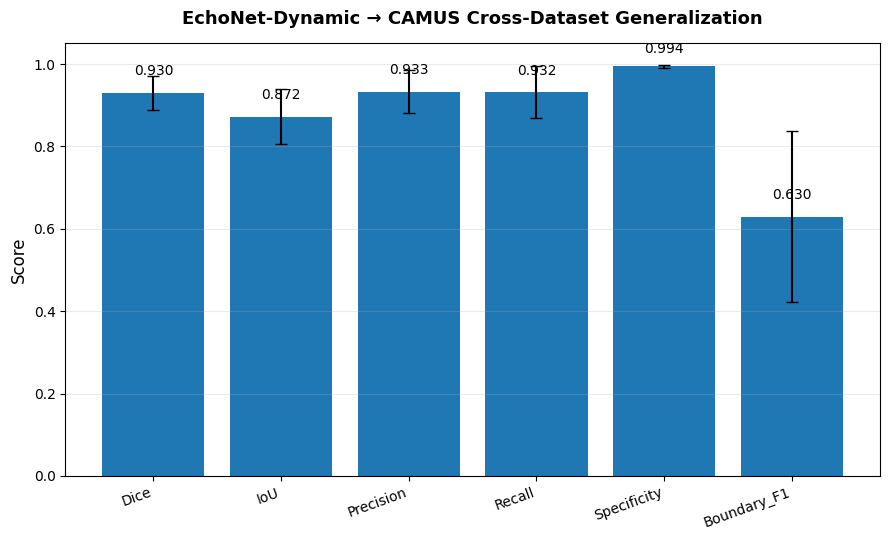

✓ Saved:
/kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_to_CAMUS/EchoNet_to_CAMUS_Generalization.png


In [141]:
# ============================================================
# CELL 9 — CROSS-DATASET PERFORMANCE FIGURE
# SAVE 400 DPI
# ============================================================

import matplotlib.pyplot as plt


plot_metrics = [
    "Dice",
    "IoU",
    "Precision",
    "Recall",
    "Specificity",
    "Boundary_F1"
]


means = [
    camus_cross_results[m].mean()
    for m in plot_metrics
]

stds = [
    camus_cross_results[m].std()
    for m in plot_metrics
]


fig, ax = plt.subplots(
    figsize=(9, 5.5)
)


bars = ax.bar(
    plot_metrics,
    means,
    yerr=stds,
    capsize=4
)


ax.set_ylabel(
    "Score",
    fontsize=12
)

ax.set_ylim(
    0,
    1.05
)

ax.set_title(
    "EchoNet-Dynamic → CAMUS Cross-Dataset Generalization",
    fontsize=13,
    fontweight="bold",
    pad=14
)


ax.grid(
    axis="y",
    alpha=0.25
)


# ------------------------------------------------------------
# VALUES ABOVE BARS
# ------------------------------------------------------------

for bar, value in zip(
    bars,
    means
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,

        min(
            value + 0.035,
            1.02
        ),

        f"{value:.3f}",

        ha="center",
        va="bottom",
        fontsize=10
    )


plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()


figure_path = os.path.join(
    CROSS_DIR,
    "EchoNet_to_CAMUS_Generalization.png"
)


plt.savefig(
    figure_path,
    dpi=400,
    bbox_inches="tight"
)

plt.show()

plt.close()


print("✓ Saved:")
print(figure_path)

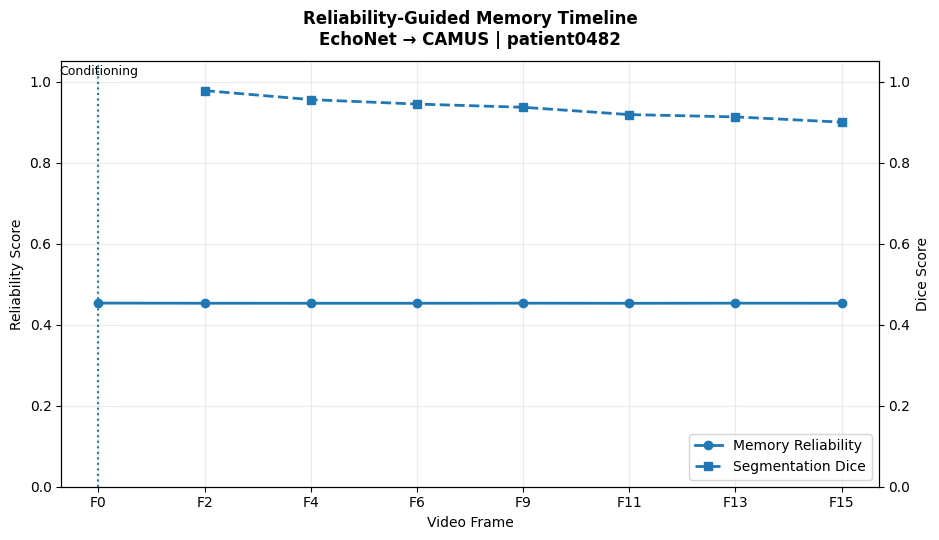

✓ Saved:
/kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_to_CAMUS/Novelty1_Reliability_Guided_Memory_Timeline.png

Reliability: [0.4534 0.453  0.453  0.453  0.4532 0.4529 0.4532 0.4531]
Dice: [   nan 0.9781 0.9558 0.9448 0.9369 0.9188 0.9131 0.9002]


In [142]:
# ============================================================
# CELL 10
# NOVELTY 1 — RELIABILITY-GUIDED MEMORY TIMELINE
# ECHONET-TRAINED -> CAMUS
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import torch


@torch.no_grad()
def get_reliability_timeline(
    model,
    loader,
    device,
    sample_index=0
):

    model.eval()

    dataset = loader.dataset

    sample = dataset[
        sample_index
    ]

    images = (
        sample["images"]
        .unsqueeze(0)
        .to(device)
    )

    masks = (
        sample["masks"]
        .unsqueeze(0)
        .to(device)
    )

    patient_id = sample[
        "patient_id"
    ]

    frame_indices = (
        sample["frame_indices"]
        .cpu()
        .numpy()
    )


    # --------------------------------------------------------
    # ONLY FRAME 0 IS CONDITIONING GT
    # --------------------------------------------------------

    predictions, reliability = (
        predict_camus_external(
            model,
            images,
            masks
        )
    )


    probs = torch.sigmoid(
        predictions
    )

    pred_masks = (
        probs > 0.5
    ).float()


    reliability_values = (
        reliability[0]
        .detach()
        .cpu()
        .numpy()
    )


    # --------------------------------------------------------
    # CALCULATE FRAME DICE
    # Frame 0 is conditioning, so Dice shown from t=1
    # --------------------------------------------------------

    dice_values = [
        np.nan
    ]


    for t in range(
        1,
        images.shape[1]
    ):

        pred = pred_masks[
            0, t, 0
        ]

        gt = masks[
            0, t, 0
        ]


        intersection = (
            pred * gt
        ).sum().item()

        denominator = (
            pred.sum().item()
            +
            gt.sum().item()
        )


        dice = (
            2.0 * intersection + 1e-6
        ) / (
            denominator + 1e-6
        )


        dice_values.append(
            dice
        )


    return (
        patient_id,
        frame_indices,
        reliability_values,
        np.asarray(dice_values)
    )


# ============================================================
# SELECT A CAMUS EXTERNAL PATIENT
# ============================================================

patient_id, frame_ids, rel_values, dice_values = (
    get_reliability_timeline(
        sam2,
        camus_external_loader,
        DEVICE,
        sample_index=0
    )
)


# ============================================================
# PLOT
# ============================================================

x = np.arange(
    len(rel_values)
)


fig, ax1 = plt.subplots(
    figsize=(9.5, 5.5)
)


# Reliability
line1 = ax1.plot(
    x,
    rel_values,
    marker="o",
    linewidth=2,
    label="Memory Reliability"
)

ax1.set_xlabel(
    "Video Frame"
)

ax1.set_ylabel(
    "Reliability Score"
)

ax1.set_ylim(
    0,
    1.05
)


# Dice
ax2 = ax1.twinx()

line2 = ax2.plot(
    x,
    dice_values,
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Segmentation Dice"
)

ax2.set_ylabel(
    "Dice Score"
)

ax2.set_ylim(
    0,
    1.05
)


# ------------------------------------------------------------
# Conditioning frame
# ------------------------------------------------------------

ax1.axvline(
    x=0,
    linestyle=":",
    linewidth=1.5
)

ax1.text(
    0,
    1.01,
    "Conditioning",
    ha="center",
    va="bottom",
    fontsize=9
)


# ------------------------------------------------------------
# Combined legend
# ------------------------------------------------------------

lines = (
    line1 +
    line2
)

labels = [
    line.get_label()
    for line in lines
]

ax1.legend(
    lines,
    labels,
    loc="lower right"
)


ax1.set_xticks(
    x
)

ax1.set_xticklabels(
    [
        f"F{int(f)}"
        for f in frame_ids
    ]
)


ax1.grid(
    alpha=0.25
)


plt.title(
    "Reliability-Guided Memory Timeline\n"
    f"EchoNet → CAMUS | {patient_id}",
    fontweight="bold",
    pad=12
)


plt.tight_layout()


timeline_path = os.path.join(
    CROSS_DIR,
    "Novelty1_Reliability_Guided_Memory_Timeline.png"
)


plt.savefig(
    timeline_path,
    dpi=400,
    bbox_inches="tight"
)

plt.show()

plt.close()


print("✓ Saved:")
print(timeline_path)

print(
    "\nReliability:",
    np.round(
        rel_values,
        4
    )
)

print(
    "Dice:",
    np.round(
        dice_values,
        4
    )
)

NOVELTY 1 — RELIABILITY ANALYSIS
N: 700
Reliability mean: 0.4530683111292975
Reliability SD: 0.00020979945496196867
Reliability min: 0.45176687836647034
Reliability max: 0.4549296498298645

Pearson: 0.2671291182434982
Spearman: 0.2900489773461395


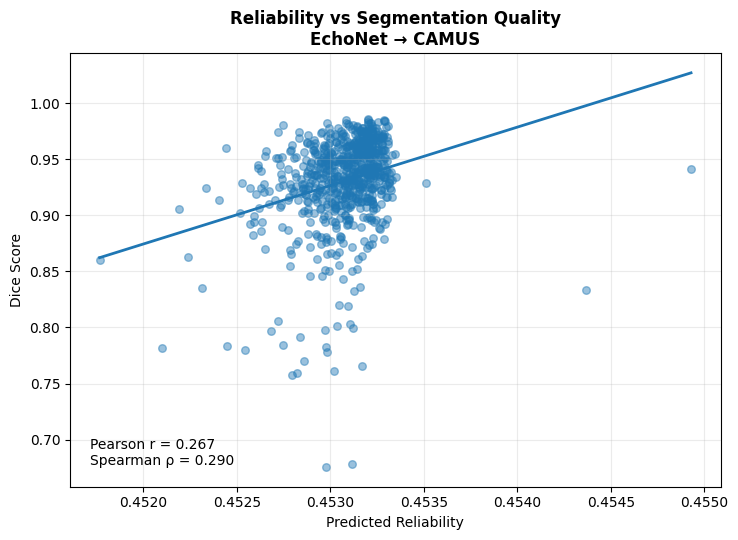


✓ Saved: /kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_to_CAMUS/Novelty1_Reliability_vs_Dice_CAMUS.png


In [143]:
# ============================================================
# CELL 11
# NOVELTY 1 — RELIABILITY ANALYSIS
# ECHONET -> CAMUS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


r = pd.to_numeric(
    camus_cross_results[
        "Reliability"
    ],
    errors="coerce"
).to_numpy()


d = pd.to_numeric(
    camus_cross_results[
        "Dice"
    ],
    errors="coerce"
).to_numpy()


valid = (
    np.isfinite(r)
    &
    np.isfinite(d)
)

r = r[valid]
d = d[valid]


print("=" * 70)
print("NOVELTY 1 — RELIABILITY ANALYSIS")
print("=" * 70)

print(
    "N:",
    len(r)
)

print(
    "Reliability mean:",
    np.mean(r)
)

print(
    "Reliability SD:",
    np.std(r)
)

print(
    "Reliability min:",
    np.min(r)
)

print(
    "Reliability max:",
    np.max(r)
)


# ------------------------------------------------------------
# CHECK WHETHER RELIABILITY ACTUALLY VARIES
# ------------------------------------------------------------

if (
    np.std(r) < 1e-6
    or
    len(
        np.unique(
            np.round(r, 6)
        )
    ) < 2
):

    print(
        "\nWARNING:"
    )

    print(
        "Reliability is nearly constant."
    )

    print(
        "Do NOT claim reliability calibration "
        "or strong Dice correlation."
    )


else:

    pearson = pd.Series(
        r
    ).corr(
        pd.Series(d),
        method="pearson"
    )

    spearman = pd.Series(
        r
    ).corr(
        pd.Series(d),
        method="spearman"
    )


    print(
        "\nPearson:",
        pearson
    )

    print(
        "Spearman:",
        spearman
    )


    # --------------------------------------------------------
    # FIGURE
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(7.5, 5.5)
    )


    ax.scatter(
        r,
        d,
        alpha=0.45,
        s=30
    )


    # Regression line
    coef = np.polyfit(
        r,
        d,
        1
    )

    xline = np.linspace(
        r.min(),
        r.max(),
        100
    )

    yline = (
        coef[0] * xline
        +
        coef[1]
    )


    ax.plot(
        xline,
        yline,
        linewidth=2
    )


    ax.set_xlabel(
        "Predicted Reliability"
    )

    ax.set_ylabel(
        "Dice Score"
    )

    ax.set_title(
        "Reliability vs Segmentation Quality\n"
        "EchoNet → CAMUS",
        fontweight="bold"
    )


    ax.grid(
        alpha=0.25
    )


    ax.text(
        0.03,
        0.05,
        (
            f"Pearson r = {pearson:.3f}\n"
            f"Spearman ρ = {spearman:.3f}"
        ),
        transform=ax.transAxes,
        fontsize=10
    )


    plt.tight_layout()


    rel_path = os.path.join(
        CROSS_DIR,
        "Novelty1_Reliability_vs_Dice_CAMUS.png"
    )


    plt.savefig(
        rel_path,
        dpi=400,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


    print(
        "\n✓ Saved:",
        rel_path
    )

NOVELTY 1 — RELIABILITY ANALYSIS
N: 700
Reliability mean: 0.4530683111292975
Reliability SD: 0.00020979945496196867
Reliability min: 0.45176687836647034
Reliability max: 0.4549296498298645

Pearson: 0.2671291182434982
Spearman: 0.2900489773461395


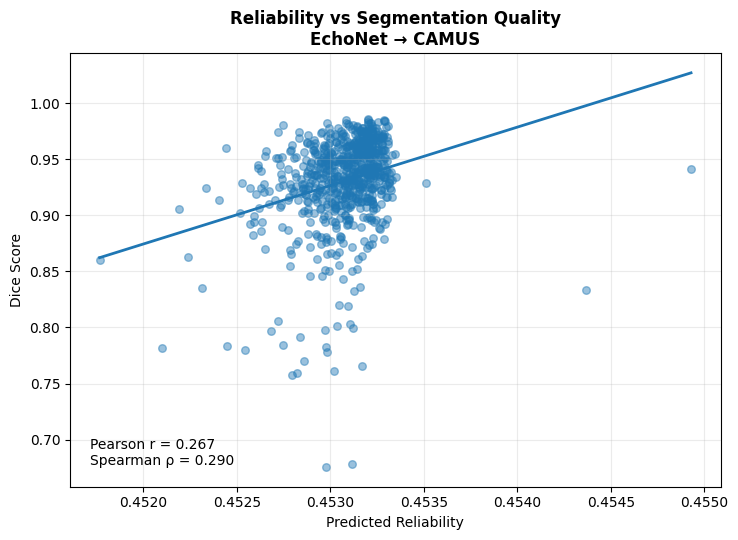


✓ Saved: /kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_to_CAMUS/Novelty1_Reliability_vs_Dice_CAMUS.png


In [144]:
# ============================================================
# CELL 11
# NOVELTY 1 — RELIABILITY ANALYSIS
# ECHONET -> CAMUS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


r = pd.to_numeric(
    camus_cross_results[
        "Reliability"
    ],
    errors="coerce"
).to_numpy()


d = pd.to_numeric(
    camus_cross_results[
        "Dice"
    ],
    errors="coerce"
).to_numpy()


valid = (
    np.isfinite(r)
    &
    np.isfinite(d)
)

r = r[valid]
d = d[valid]


print("=" * 70)
print("NOVELTY 1 — RELIABILITY ANALYSIS")
print("=" * 70)

print(
    "N:",
    len(r)
)

print(
    "Reliability mean:",
    np.mean(r)
)

print(
    "Reliability SD:",
    np.std(r)
)

print(
    "Reliability min:",
    np.min(r)
)

print(
    "Reliability max:",
    np.max(r)
)


# ------------------------------------------------------------
# CHECK WHETHER RELIABILITY ACTUALLY VARIES
# ------------------------------------------------------------

if (
    np.std(r) < 1e-6
    or
    len(
        np.unique(
            np.round(r, 6)
        )
    ) < 2
):

    print(
        "\nWARNING:"
    )

    print(
        "Reliability is nearly constant."
    )

    print(
        "Do NOT claim reliability calibration "
        "or strong Dice correlation."
    )


else:

    pearson = pd.Series(
        r
    ).corr(
        pd.Series(d),
        method="pearson"
    )

    spearman = pd.Series(
        r
    ).corr(
        pd.Series(d),
        method="spearman"
    )


    print(
        "\nPearson:",
        pearson
    )

    print(
        "Spearman:",
        spearman
    )


    # --------------------------------------------------------
    # FIGURE
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(7.5, 5.5)
    )


    ax.scatter(
        r,
        d,
        alpha=0.45,
        s=30
    )


    # Regression line
    coef = np.polyfit(
        r,
        d,
        1
    )

    xline = np.linspace(
        r.min(),
        r.max(),
        100
    )

    yline = (
        coef[0] * xline
        +
        coef[1]
    )


    ax.plot(
        xline,
        yline,
        linewidth=2
    )


    ax.set_xlabel(
        "Predicted Reliability"
    )

    ax.set_ylabel(
        "Dice Score"
    )

    ax.set_title(
        "Reliability vs Segmentation Quality\n"
        "EchoNet → CAMUS",
        fontweight="bold"
    )


    ax.grid(
        alpha=0.25
    )


    ax.text(
        0.03,
        0.05,
        (
            f"Pearson r = {pearson:.3f}\n"
            f"Spearman ρ = {spearman:.3f}"
        ),
        transform=ax.transAxes,
        fontsize=10
    )


    plt.tight_layout()


    rel_path = os.path.join(
        CROSS_DIR,
        "Novelty1_Reliability_vs_Dice_CAMUS.png"
    )


    plt.savefig(
        rel_path,
        dpi=400,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


    print(
        "\n✓ Saved:",
        rel_path
    )

Topology valid: 32.14%
Fragmented: 57.86%
Contains hole: 49.86%


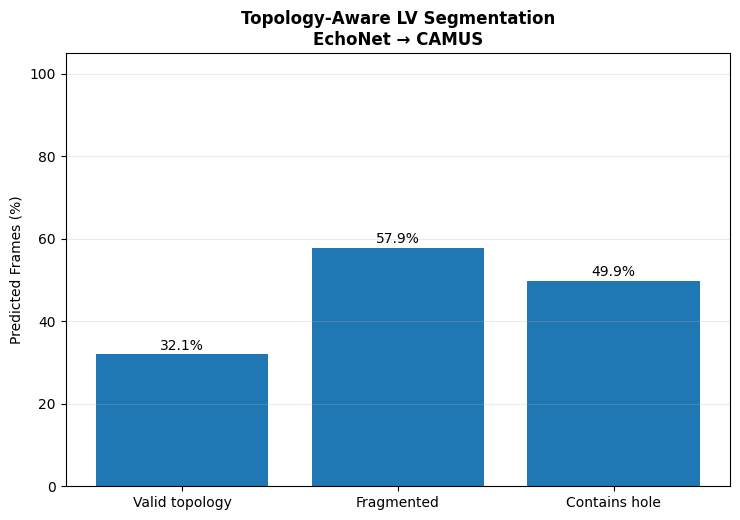

✓ Saved: /kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_to_CAMUS/Novelty2_Topology_Validity_CAMUS.png


In [145]:
# ============================================================
# CELL 12
# NOVELTY 2 — TOPOLOGY VALIDITY
# ECHONET -> CAMUS
# ============================================================

from scipy.ndimage import (
    label as cc_label,
    binary_fill_holes
)


def binary_topology_stats(
    mask
):

    m = mask.astype(
        bool
    )

    if m.sum() == 0:

        return (
            0,
            0,
            0.0
        )


    _, n_components = cc_label(
        m
    )


    filled = binary_fill_holes(
        m
    )

    hole_pixels = np.logical_and(
        filled,
        ~m
    )

    has_hole = int(
        hole_pixels.any()
    )


    valid = float(
        n_components == 1
        and
        has_hole == 0
    )


    return (
        int(n_components),
        has_hole,
        valid
    )


@torch.no_grad()
def evaluate_camus_topology(
    model,
    loader
):

    model.eval()

    rows = []


    for batch_idx, batch in enumerate(
        loader
    ):

        images = batch[
            "images"
        ].to(
            DEVICE
        )

        masks = batch[
            "masks"
        ].to(
            DEVICE
        )

        patient = batch[
            "patient_id"
        ][0]


        pred, rel = (
            predict_camus_external(
                model,
                images,
                masks
            )
        )


        pm = (
            torch.sigmoid(
                pred[:, 1:]
            )
            > 0.5
        ).cpu().numpy().astype(
            np.uint8
        )


        for t in range(
            pm.shape[1]
        ):

            components, hole, valid = (
                binary_topology_stats(
                    pm[0, t, 0]
                )
            )


            rows.append({

                "Patient":
                    patient,

                "Frame":
                    t + 1,

                "Components":
                    components,

                "Contains_Hole":
                    hole,

                "Topology_Valid":
                    valid
            })


    return pd.DataFrame(
        rows
    )


camus_topology_results = (
    evaluate_camus_topology(
        sam2,
        camus_external_loader
    )
)


# ------------------------------------------------------------
# SAVE CSV
# ------------------------------------------------------------

camus_topology_results.to_csv(
    os.path.join(
        CROSS_DIR,
        "Novelty2_CAMUS_Topology_Results.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

valid_pct = (
    camus_topology_results[
        "Topology_Valid"
    ].mean()
    * 100
)

fragmented_pct = (
    (
        camus_topology_results[
            "Components"
        ] > 1
    ).mean()
    * 100
)

hole_pct = (
    camus_topology_results[
        "Contains_Hole"
    ].mean()
    * 100
)


print(
    "Topology valid:",
    f"{valid_pct:.2f}%"
)

print(
    "Fragmented:",
    f"{fragmented_pct:.2f}%"
)

print(
    "Contains hole:",
    f"{hole_pct:.2f}%"
)


# ------------------------------------------------------------
# FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7.5, 5.3)
)


labels = [
    "Valid topology",
    "Fragmented",
    "Contains hole"
]

values = [
    valid_pct,
    fragmented_pct,
    hole_pct
]


bars = ax.bar(
    labels,
    values
)


ax.set_ylabel(
    "Predicted Frames (%)"
)

ax.set_ylim(
    0,
    max(
        105,
        max(values) + 10
    )
)


ax.set_title(
    "Topology-Aware LV Segmentation\n"
    "EchoNet → CAMUS",
    fontweight="bold"
)


for bar, value in zip(
    bars,
    values
):

    ax.text(
        bar.get_x()
        + bar.get_width()/2,

        value + 1,

        f"{value:.1f}%",

        ha="center",
        fontsize=10
    )


ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()


topology_path = os.path.join(
    CROSS_DIR,
    "Novelty2_Topology_Validity_CAMUS.png"
)


plt.savefig(
    topology_path,
    dpi=400,
    bbox_inches="tight"
)

plt.show()

plt.close()


print(
    "✓ Saved:",
    topology_path
)

Mean area jitter: 0.03224401097123822
Mean centroid jitter: 0.005774044921223928


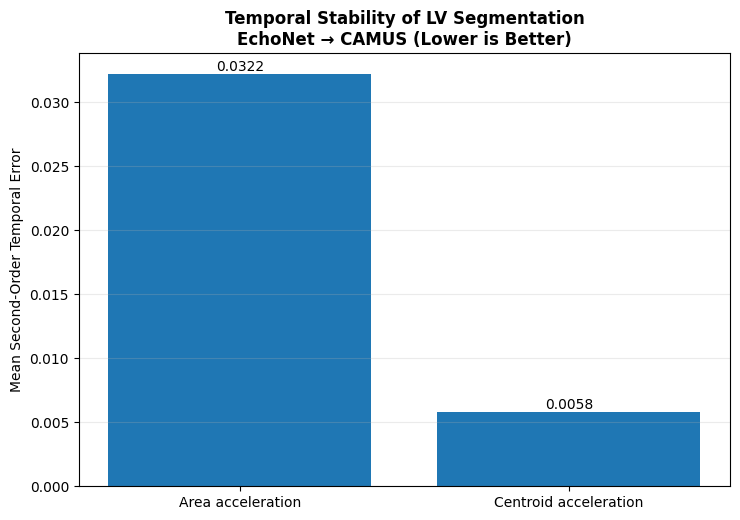

✓ Saved: /kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_to_CAMUS/Novelty3_SecondOrder_Temporal_Stability_CAMUS.png


In [146]:
# ============================================================
# CELL 13
# NOVELTY 3 — SECOND-ORDER TEMPORAL STABILITY
# ECHONET -> CAMUS
# ============================================================

@torch.no_grad()
def evaluate_camus_temporal_jitter(
    model,
    loader
):

    model.eval()

    area_jitter = []
    centroid_jitter = []


    for batch in loader:

        images = batch[
            "images"
        ].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch[
            "masks"
        ].to(
            DEVICE,
            non_blocking=True
        )


        pred, rel = (
            predict_camus_external(
                model,
                images,
                masks
            )
        )


        p = torch.sigmoid(
            pred
        )


        # ----------------------------------------------------
        # SECOND-ORDER TEMPORAL DIFFERENCES
        # ----------------------------------------------------

        for t in range(
            2,
            p.shape[1]
        ):

            a0 = soft_area(
                p[:, t-2]
            )

            a1 = soft_area(
                p[:, t-1]
            )

            a2 = soft_area(
                p[:, t]
            )


            c0 = soft_centroid(
                p[:, t-2]
            )

            c1 = soft_centroid(
                p[:, t-1]
            )

            c2 = soft_centroid(
                p[:, t]
            )


            area_acceleration = (
                torch.abs(
                    a2
                    - 2*a1
                    + a0
                )
                /
                (
                    a1
                    + EPS
                )
            )


            centroid_acceleration = (
                torch.norm(
                    c2
                    - 2*c1
                    + c0,
                    dim=-1
                )
            )


            area_jitter.extend(
                area_acceleration
                .cpu()
                .numpy()
                .tolist()
            )

            centroid_jitter.extend(
                centroid_acceleration
                .cpu()
                .numpy()
                .tolist()
            )


    return (
        np.asarray(
            area_jitter
        ),
        np.asarray(
            centroid_jitter
        )
    )


camus_area_jitter, camus_centroid_jitter = (
    evaluate_camus_temporal_jitter(
        sam2,
        camus_external_loader
    )
)


# ------------------------------------------------------------
# SAVE RAW VALUES
# ------------------------------------------------------------

pd.DataFrame({

    "Area_Jitter":
        camus_area_jitter,

    "Centroid_Jitter":
        camus_centroid_jitter

}).to_csv(

    os.path.join(
        CROSS_DIR,
        "Novelty3_CAMUS_Temporal_Jitter.csv"
    ),

    index=False
)


print(
    "Mean area jitter:",
    camus_area_jitter.mean()
)

print(
    "Mean centroid jitter:",
    camus_centroid_jitter.mean()
)


# ------------------------------------------------------------
# FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7.5, 5.3)
)


values = [

    camus_area_jitter.mean(),

    camus_centroid_jitter.mean()
]


bars = ax.bar(

    [
        "Area acceleration",
        "Centroid acceleration"
    ],

    values
)


ax.set_ylabel(
    "Mean Second-Order Temporal Error"
)

ax.set_title(
    "Temporal Stability of LV Segmentation\n"
    "EchoNet → CAMUS (Lower is Better)",
    fontweight="bold"
)


for bar, value in zip(
    bars,
    values
):

    ax.text(

        bar.get_x()
        + bar.get_width()/2,

        value,

        f"{value:.4f}",

        ha="center",
        va="bottom",
        fontsize=10
    )


ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()


temporal_path = os.path.join(
    CROSS_DIR,
    "Novelty3_SecondOrder_Temporal_Stability_CAMUS.png"
)


plt.savefig(
    temporal_path,
    dpi=400,
    bbox_inches="tight"
)

plt.show()

plt.close()


print(
    "✓ Saved:",
    temporal_path
)

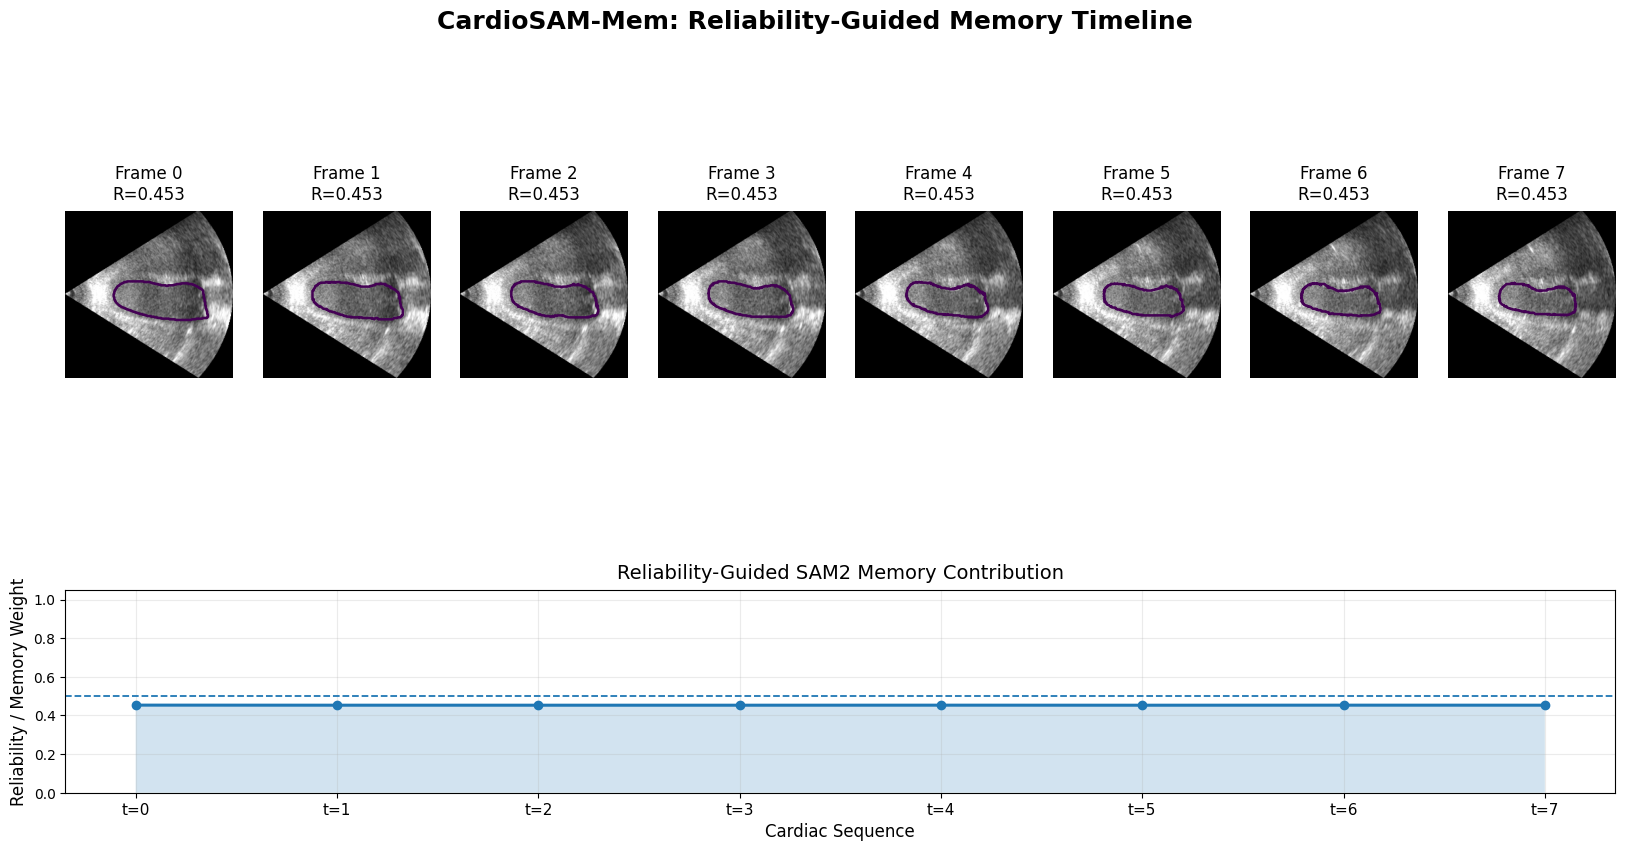

NOVELTY 1 — RELIABILITY-GUIDED MEMORY
Training dataset : EchoNet-Dynamic
External dataset : CAMUS 4CH
Patient          : patient0482
Reliability      : [0.4534 0.453  0.453  0.453  0.4532 0.4529 0.4532 0.4531]
Mean reliability : 0.4531

✓ Saved: /kaggle/working/CardioSAM_Mem_EchoNet_Evaluation/EchoNet_to_CAMUS/Novelty1_Reliability_Guided_Memory_Timeline_CAMUS.png


In [147]:
# ============================================================
# NOVELTY 1 — RELIABILITY-GUIDED MEMORY TIMELINE
# ECHONET-TRAINED MODEL -> CAMUS
# SAME STYLE AS PREVIOUS EXPERIMENT
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import torch


@torch.no_grad()
def create_reliability_memory_timeline(
    model,
    loader,
    device,
    sample_index=0
):

    model.eval()

    # --------------------------------------------------------
    # GET CAMUS PATIENT
    # --------------------------------------------------------

    sample = loader.dataset[sample_index]

    images = (
        sample["images"]
        .unsqueeze(0)
        .to(device)
    )

    masks = (
        sample["masks"]
        .unsqueeze(0)
        .to(device)
    )

    patient_id = sample["patient_id"]


    # --------------------------------------------------------
    # ECHONET-TRAINED MODEL -> CAMUS
    # --------------------------------------------------------

    predictions, reliability = (
        predict_camus_external(
            model,
            images,
            masks
        )
    )


    probabilities = torch.sigmoid(
        predictions
    )

    pred_masks = (
        probabilities > 0.5
    ).float()


    reliability_values = (
        reliability[0]
        .detach()
        .cpu()
        .numpy()
    )


    images_np = (
        images[0, :, 0]
        .detach()
        .cpu()
        .numpy()
    )


    masks_np = (
        pred_masks[0, :, 0]
        .detach()
        .cpu()
        .numpy()
    )


    T = images_np.shape[0]


    # ========================================================
    # FIGURE
    # ========================================================

    fig = plt.figure(
        figsize=(20, 9)
    )


    gs = fig.add_gridspec(
        2,
        T,
        height_ratios=[
            2.4,
            1.25
        ],
        hspace=0.34,
        wspace=0.18
    )


    # ========================================================
    # TOP ROW — CARDIAC SEQUENCE + PREDICTED CONTOURS
    # ========================================================

    for t in range(T):

        ax = fig.add_subplot(
            gs[0, t]
        )


        ax.imshow(
            images_np[t],
            cmap="gray"
        )


        # ----------------------------------------------------
        # PREDICTED LV CONTOUR
        # ----------------------------------------------------

        if masks_np[t].sum() > 0:

            ax.contour(
                masks_np[t],
                levels=[0.5],
                linewidths=1.8
            )


        # ----------------------------------------------------
        # FRAME + RELIABILITY
        # ----------------------------------------------------

        ax.set_title(
            f"Frame {t}\n"
            f"R={reliability_values[t]:.3f}",
            fontsize=12,
            pad=8
        )


        ax.axis(
            "off"
        )


    # ========================================================
    # BOTTOM ROW — RELIABILITY / MEMORY CONTRIBUTION
    # ========================================================

    ax_mem = fig.add_subplot(
        gs[1, :]
    )


    x = np.arange(
        T
    )


    ax_mem.plot(
        x,
        reliability_values,
        marker="o",
        linewidth=2.2
    )


    ax_mem.fill_between(
        x,
        0,
        reliability_values,
        alpha=0.20
    )


    # --------------------------------------------------------
    # REFERENCE LINE = 0.5
    # --------------------------------------------------------

    ax_mem.axhline(
        y=0.5,
        linestyle="--",
        linewidth=1.3
    )


    ax_mem.set_xticks(
        x
    )


    ax_mem.set_xticklabels(
        [
            f"t={i}"
            for i in range(T)
        ],
        fontsize=11
    )


    ax_mem.set_ylim(
        0,
        1.05
    )


    ax_mem.set_xlabel(
        "Cardiac Sequence",
        fontsize=12
    )


    ax_mem.set_ylabel(
        "Reliability / Memory Weight",
        fontsize=12
    )


    ax_mem.set_title(
        "Reliability-Guided SAM2 Memory Contribution",
        fontsize=14,
        pad=8
    )


    ax_mem.grid(
        alpha=0.25
    )


    # ========================================================
    # MAIN TITLE
    # ========================================================

    fig.suptitle(
        "CardioSAM-Mem: Reliability-Guided Memory Timeline",
        fontsize=18,
        fontweight="bold",
        y=0.98
    )


    # ========================================================
    # SAVE
    # ========================================================

    save_path = os.path.join(
        CROSS_DIR,
        "Novelty1_Reliability_Guided_Memory_Timeline_CAMUS.png"
    )


    plt.savefig(
        save_path,
        dpi=400,
        bbox_inches="tight",
        pad_inches=0.15
    )


    plt.show()

    plt.close()


    # ========================================================
    # PRINT VALUES
    # ========================================================

    print("=" * 70)

    print(
        "NOVELTY 1 — RELIABILITY-GUIDED MEMORY"
    )

    print("=" * 70)

    print(
        "Training dataset : EchoNet-Dynamic"
    )

    print(
        "External dataset : CAMUS 4CH"
    )

    print(
        "Patient          :",
        patient_id
    )

    print(
        "Reliability      :",
        np.round(
            reliability_values,
            4
        )
    )

    print(
        "Mean reliability :",
        round(
            float(
                np.mean(
                    reliability_values
                )
            ),
            4
        )
    )

    print(
        "\n✓ Saved:",
        save_path
    )


    return {
        "patient_id":
            patient_id,

        "reliability":
            reliability_values,

        "save_path":
            save_path
    }


# ============================================================
# RUN
# ============================================================

novelty1_camus = (
    create_reliability_memory_timeline(
        sam2,
        camus_external_loader,
        DEVICE,
        sample_index=0
    )
)